# Laboratorio 3 - La tarea de clasificación

**Integrantes:**
- Juan Diego Quintero Alvarez - 202412750
- Juan Jose Penha Pulido - 202312307

**Fecha:** 19 de octubre de 2026

**Caso Ruta Alpes.** La empresa quiere dejar de mandarle el mismo cupón a todo el mundo. Con escenarios de conducción, datos demográficos y hábitos de consumo de los conductores, en este notebook construimos modelos que predicen si un conductor acepta un cupón de **Cafetería** o de **Restaurante(&lt;20)**. Comparamos regresión logística, árboles de decisión y Random Forest, probamos si balancear las clases ayuda en Restaurante(&lt;20) y al final discutimos qué tan buena idea es personalizar ofertas con variables como la edad, el género o el ingreso.

## 0. Organización del trabajo

El modelado lo repartimos por tipo de cupón: Juan José se encargó de los modelos de Cafetería y Juan Diego de los de Restaurante(&lt;20), incluida la prueba con SMOTE. La exploración, la limpieza, la tabla comparativa, las variables relevantes, el análisis de resultados y las predicciones finales las hicimos entre los dos.

Algo que decidimos desde el principio fue usar exactamente la misma limpieza, el mismo preprocesamiento y las mismas grillas de hiperparámetros para los dos cupones. Así, cuando un resultado cambia de un cupón al otro, sabemos que es por los datos y no porque cada uno haya hecho las cosas a su manera.

## 1. Librerías y configuración

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, StratifiedGroupKFold,
    cross_val_predict, cross_val_score, cross_validate,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    classification_report, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay,
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid", rc={"grid.color": "#e1e0d9", "axes.edgecolor": "#c3c2b7",
                                     "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.html.use_mathjax", False)  # que MathJax no lea los "$" de ingreso como fórmulas

RANDOM_STATE = 42
CUPONES = ["Cafetería", "Restaurante(<20)"]
COLORES = {"Cafetería": "#2a78d6", "Restaurante(<20)": "#eb6834"}

## 2. Carga de datos

Trabajamos con tres archivos:

- `Lab3_Datos.xlsx`: los escenarios etiquetados, con la columna `acepta_cupon` (Sí / No).
- `Lab3_datos_Prueba.xlsx`: 20 escenarios sin etiqueta (10 de Cafetería y 10 de Restaurante(&lt;20)) sobre los que hay que entregar predicciones.
- `Lab3_diccionario_Datos.xlsx`: el diccionario de datos, que usamos para revisar el tipo de cada variable y los valores que puede tomar.

El archivo etiquetado trae los cinco tipos de cupón del estudio, pero aquí solo nos interesan dos. Cada uno se modela por separado: no hay por qué pensar que alguien decide igual frente a un café que frente a un almuerzo, y en la exploración se ve que efectivamente no es así.

In [2]:
df = pd.read_excel("Lab3_Datos.xlsx")
df_test_full = pd.read_excel("Lab3_datos_Prueba.xlsx")
diccionario = pd.read_excel("Lab3_diccionario_Datos.xlsx")

print(f"Datos etiquetados: {df.shape}")
print(f"Datos de prueba (sin etiquetar): {df_test_full.shape}\n")
print("Registros por tipo de cupón:")
print(df["cupon"].value_counts())
print("\nTipos de cupón en el archivo de prueba:")
print(df_test_full["cupon"].value_counts())

Datos etiquetados: (12664, 26)
Datos de prueba (sin etiquetar): (20, 25)

Registros por tipo de cupón:
cupon
Cafetería             3986
Restaurante(<20)      2776
Comida para llevar    2393
Bar                   2017
Restaurante(20-50)    1492
Name: count, dtype: int64

Tipos de cupón en el archivo de prueba:
cupon
Cafetería           10
Restaurante(<20)    10
Name: count, dtype: int64


In [3]:
df.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


## 3. Actividad 1: Exploración de los datos

Revisamos los dos subconjuntos por separado. Primero la calidad de los datos, mirando cuatro cosas: completitud (faltantes), unicidad (duplicados), validez (que los valores tengan sentido según el diccionario, incluidos los atípicos) y consistencia (que las variables no se contradigan entre sí). Después miramos cómo cambia la aceptación con cada variable, porque eso es lo que luego nos ayuda a entender qué aprenden los modelos.

### 3.1 Vista general de las variables

In [4]:
subconjuntos = {c: df[df["cupon"] == c] for c in CUPONES}

resumen = pd.DataFrame({
    "Tipo (diccionario)": diccionario.set_index("Variable")["Tipo"],
    "Valores únicos": df.nunique(),
    "% faltantes Cafetería": subconjuntos["Cafetería"].isna().mean() * 100,
    "% faltantes Restaurante(<20)": subconjuntos["Restaurante(<20)"].isna().mean() * 100,
}).loc[df.columns].round(2)
resumen

,Tipo (diccionario),Valores únicos,% faltantes Cafetería,% faltantes Restaurante(<20)
destino,Categórica nominal,3,0.00,0.00
acompanante,Categórica nominal,4,0.00,0.00
clima,Categórica nominal,3,0.00,0.00
temperatura,Numérica entero,3,0.00,0.00
hora,Categórica ordinal,5,0.00,0.00
cupon,Categórica nominal,5,0.00,0.00
vigencia_cupon,Categórica nominal,2,0.00,0.00
genero,Categórica nominal,2,0.00,0.00
edad,Categórica ordinal,8,0.00,0.00
estado_civil,Categórica nominal,5,0.00,0.00


Lo primero que salta a la vista es que casi todo es categórico. De las 26 columnas, la única numérica es `temperatura`, y aun así solo toma tres valores (30, 55 y 80 °F). Entonces la parte delicada de la preparación va a ser la codificación, más que el escalamiento o el manejo de atípicos numéricos.

También aparecen desde ya varios problemas: `vehiculo` está vacía en el 99% de las filas, `tiempo_cupon_mayor_5min` tiene un único valor y `ocupacion` tiene 25 categorías, lo que al codificarla va a generar muchas columnas con pocos casos cada una. Los faltantes de las variables de frecuencia son pocos (menos del 2%) y muy parecidos en los dos subconjuntos.

### 3.2 Distribución de `acepta_cupon` en cada subconjunto

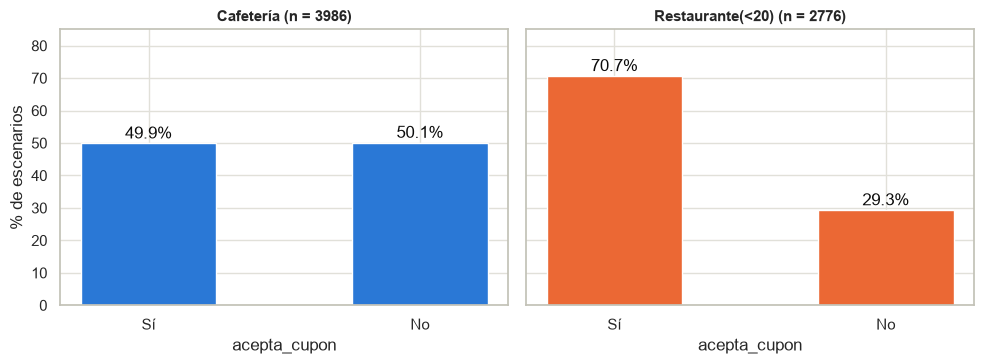

Cafetería: Sí = 1989, No = 1997 -> razón mayoritaria/minoritaria = 1.00
Restaurante(<20): Sí = 1962, No = 814 -> razón mayoritaria/minoritaria = 2.41


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, cupon in zip(axes, CUPONES):
    dist = subconjuntos[cupon]["acepta_cupon"].value_counts(normalize=True).reindex(["Sí", "No"]) * 100
    ax.bar(dist.index, dist.values, color=COLORES[cupon], width=0.5)
    for i, v in enumerate(dist.values):
        ax.text(i, v + 1.5, f"{v:.1f}%", ha="center", color="#0b0b0b")
    ax.set_title(f"{cupon} (n = {len(subconjuntos[cupon])})")
    ax.set_xlabel("acepta_cupon")
    ax.set_ylim(0, 85)
axes[0].set_ylabel("% de escenarios")
plt.tight_layout()
plt.show()

for cupon in CUPONES:
    conteo = subconjuntos[cupon]["acepta_cupon"].value_counts()
    print(f"{cupon}: Sí = {conteo['Sí']}, No = {conteo['No']} "
          f"-> razón mayoritaria/minoritaria = {conteo.max() / conteo.min():.2f}")

Aquí está la diferencia más importante entre los dos cupones. En Cafetería la variable objetivo está prácticamente partida a la mitad (49.9% Sí y 50.1% No), así que no hay desbalance. En Restaurante(&lt;20), en cambio, el 70.7% de los escenarios terminan en "Sí" y la clase minoritaria es **"No"**, con una razón de 2.41 a 1.

Ese desbalance no es extremo, pero sí cambia la forma de evaluar. Un modelo que dijera "Sí" a todo en Restaurante(&lt;20) ya tendría 70.7% de accuracy y un F1 cercano a 0.83 para la clase "Sí", sin haber aprendido nada. Por eso en Restaurante(&lt;20) vamos a mirar siempre el recall de la clase "No", que es justamente la que le interesa a Ruta Alpes para no mandar notificaciones que nadie va a usar. También por eso la prueba con SMOTE (actividad 6) se hace solo en Restaurante(&lt;20): en Cafetería no hay nada que balancear.

### 3.3 Completitud (valores faltantes)

,Cafetería,Restaurante(<20),Cafetería (%),Restaurante(<20) (%)
vehiculo,3949,2751,99.07,99.10
frecuencia_bar,37,23,0.93,0.83
frecuencia_cafeteria,72,47,1.81,1.69
frecuencia_comida_para_llevar,57,34,1.43,1.22
frecuencia_restaurante_menos_20,50,27,1.25,0.97
frecuencia_restaurante_20_a_50,55,43,1.38,1.55


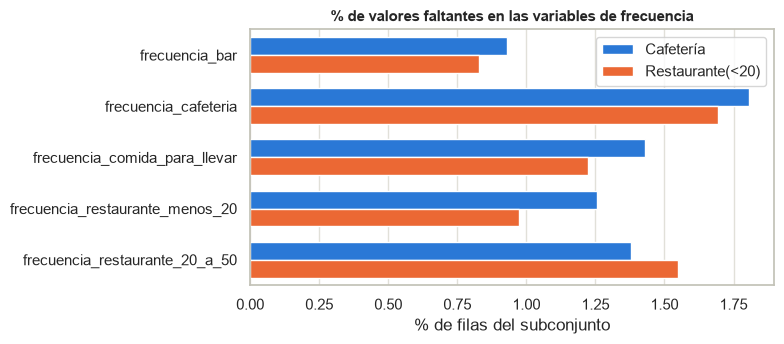

Número de frecuencias vacías por fila (0 = fila completa):
  Cafetería: {0: 3806, 1: 152, 2: 7, 5: 21}
  Restaurante(<20): {0: 2643, 1: 119, 2: 5, 5: 9}


In [6]:
faltantes = pd.DataFrame({c: s.isna().sum() for c, s in subconjuntos.items()})
faltantes = faltantes[faltantes.sum(axis=1) > 0]
tamanos = pd.Series({c: len(s) for c, s in subconjuntos.items()})
display(faltantes.join((faltantes / tamanos * 100).round(2), rsuffix=" (%)"))

cols_frec = [c for c in df.columns if c.startswith("frecuencia_")]
pct_frec = (faltantes.loc[cols_frec] / tamanos * 100).reset_index(names="Variable")
pct_frec = pct_frec.melt(id_vars="Variable", var_name="Cupón", value_name="% faltante")

plt.figure(figsize=(8, 3.6))
sns.barplot(data=pct_frec, y="Variable", x="% faltante", hue="Cupón", palette=COLORES, width=0.7, saturation=1)
plt.title("% de valores faltantes en las variables de frecuencia")
plt.xlabel("% de filas del subconjunto")
plt.ylabel("")
plt.legend(title=None)
plt.tight_layout()
plt.show()

print("Número de frecuencias vacías por fila (0 = fila completa):")
for cupon, s in subconjuntos.items():
    print(f"  {cupon}: {s[cols_frec].isna().sum(axis=1).value_counts().sort_index().to_dict()}")

`vehiculo` está vacía en más del 99% de las filas (solo 37 filas de Cafetería y 25 de Restaurante(&lt;20) tienen dato), así que no hay forma razonable de imputarla: cualquier valor que pusiéramos sería inventado. La eliminamos.

Las variables de frecuencia tienen entre 0.8% y 1.8% de faltantes. Mirando cuántos huecos tiene cada fila, la mayoría tiene uno solo, pero hay un grupo (21 filas en Cafetería y 9 en Restaurante(&lt;20)) donde faltan las cinco frecuencias a la vez; parece gente que simplemente se saltó ese bloque de la encuesta. Si elimináramos todas las filas con algún faltante perderíamos entre el 4.5% y el 4.8% de los datos, y nos pareció demasiado para tan pocos vacíos. Preferimos imputar con la moda, que es razonable para variables categóricas con tan poca pérdida, y hacerlo **dentro del pipeline**, para que la moda se calcule solo con los datos de entrenamiento de cada fold.

### 3.4 Unicidad (registros duplicados)

In [7]:
PERFIL = ["genero", "edad", "estado_civil", "tiene_hijos", "educacion", "ocupacion", "ingreso"] + cols_frec

for cupon, s in subconjuntos.items():
    variables = list(s.columns.drop("acepta_cupon"))
    respuestas = s.drop_duplicates().groupby(variables, dropna=False)["acepta_cupon"].nunique()
    n_perfiles = s[PERFIL].drop_duplicates().shape[0]
    print(f"{cupon}:")
    print(f"  duplicados exactos: {s.duplicated().sum()}")
    print(f"  grupos con las mismas variables pero distinta respuesta: {(respuestas > 1).sum()}")
    print(f"  perfiles distintos de conductor: {n_perfiles} "
          f"(~{len(s) / n_perfiles:.1f} escenarios por conductor)")

Cafetería:
  duplicados exactos: 7
  grupos con las mismas variables pero distinta respuesta: 4
  perfiles distintos de conductor: 565 (~7.1 escenarios por conductor)
Restaurante(<20):
  duplicados exactos: 7
  grupos con las mismas variables pero distinta respuesta: 3
  perfiles distintos de conductor: 567 (~4.9 escenarios por conductor)


Hay 7 filas exactamente duplicadas en cada subconjunto y las eliminamos: no aportan información nueva y, si una copia queda en train y la otra en test, el modelo estaría "viendo" parte del test.

Además encontramos 4 casos en Cafetería y 3 en Restaurante(&lt;20) donde todas las variables son idénticas pero la respuesta cambia. Esos no los tocamos, porque no hay forma de saber cuál respuesta es la "correcta"; es ruido normal de una encuesta y el modelo simplemente no va a poder acertar ambos.

Lo más interesante de esta parte es que las filas no son de personas distintas. Con las variables de perfil (demografía y hábitos) contamos unos 565 conductores diferentes, cada uno con unos 7 escenarios de Cafetería y unos 5 de Restaurante(&lt;20). Eso no es un error de unicidad, pero sí significa que las filas no son independientes: al partir en train y test al azar, el mismo conductor queda en los dos lados. Lo retomamos en el análisis (sección 11), porque afecta qué tan optimistas son las métricas.

### 3.5 Validez y valores atípicos

In [8]:
FREQ_ORDER = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]

# Variables ordinales con el orden que trae el diccionario de datos
ORDINAL_CATEGORIES = {
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": [
        "Bachillerato incompleto", "Bachillerato completo",
        "Estudios universitarios sin título", "Técnico/Tecnólogo",
        "Pregrado", "Posgrado (Maestría o Doctorado)",
    ],
    "ingreso": [
        "Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499",
        "$37.500 - $49.999", "$50.000 - $62.499", "$62.500 - $74.999",
        "$75.000 - $87.499", "$87.500 - $99.999", "$100.000 o más",
    ],
    "frecuencia_bar": FREQ_ORDER,
    "frecuencia_cafeteria": FREQ_ORDER,
    "frecuencia_comida_para_llevar": FREQ_ORDER,
    "frecuencia_restaurante_menos_20": FREQ_ORDER,
    "frecuencia_restaurante_20_a_50": FREQ_ORDER,
}

SI_NO = ["Sí", "No"]
DOMINIOS = {
    **ORDINAL_CATEGORIES,
    "destino": ["Casa", "Sin lugar urgente", "Trabajo"],
    "acompanante": ["Solo", "Amigo(s)", "Hijo(s)", "Pareja"],
    "clima": ["Soleado", "Lluvioso", "Nevado"],
    "temperatura": [30, 55, 80],
    "cupon": ["Bar", "Cafetería", "Comida para llevar", "Restaurante(<20)", "Restaurante(20-50)"],
    "vigencia_cupon": ["2 horas", "1 día"],
    "genero": ["Femenino", "Masculino"],
    "estado_civil": ["Soltero(a)", "Casado(a)", "Unión libre", "Divorciado(a)", "Viudo(a)"],
    "vehiculo": ["Mazda5", "Scooter o motocicleta", "Camioneta tipo crossover",
                 "Carro muy viejo para instalarle Onstar", "No conduce"],
    "tiene_hijos": SI_NO, "tiempo_cupon_mayor_5min": SI_NO, "tiempo_cupon_mayor_15min": SI_NO,
    "tiempo_cupon_mayor_25min": SI_NO, "misma_direccion": SI_NO, "direccion_opuesta": SI_NO,
    "acepta_cupon": SI_NO,
}

print("Valores que no están en el dominio definido por el diccionario:")
for col, dominio in DOMINIOS.items():
    fuera = set(df[col].dropna().unique()) - set(dominio)
    if fuera:
        print(f"  {col}: {sorted(fuera)}")
print(f"ocupacion: {df['ocupacion'].nunique()} categorías (el diccionario habla de 25)")

print("\nEstadísticas de la única variable numérica:")
display(df.groupby("cupon")["temperatura"].describe().loc[CUPONES])

def combinaciones_raras(s):
    return pd.Series({
        "Jubilado(a) con 26 años o menos": (
            (s["ocupacion"] == "Jubilado(a)") & s["edad"].isin(["menor de 21", "21", "26"])).sum(),
        "Posgrado con 21 años o menos": (
            (s["educacion"] == "Posgrado (Maestría o Doctorado)") & s["edad"].isin(["menor de 21", "21"])).sum(),
        "Pregrado terminado siendo menor de 21": (
            (s["educacion"] == "Pregrado") & (s["edad"] == "menor de 21")).sum(),
    })

print("Combinaciones poco usuales (posibles atípicos de perfil):")
pd.DataFrame({c: combinaciones_raras(s) for c, s in subconjuntos.items()})

Valores que no están en el dominio definido por el diccionario:
  vehiculo: ['Carro muy viejo para instalarle Onstar :D']
ocupacion: 25 categorías (el diccionario habla de 25)

Estadísticas de la única variable numérica:


,count,mean,std,min,25%,50%,75%,max
cupon,,,,,,,,
Cafetería,3986.0,68.026844,15.992518,30.0,55.0,80.0,80.0,80.0
Restaurante(<20),2776.0,64.176873,19.790289,30.0,55.0,80.0,80.0,80.0


Combinaciones poco usuales (posibles atípicos de perfil):


,Cafetería,Restaurante(<20)
Jubilado(a) con 26 años o menos,10,4
Posgrado con 21 años o menos,18,8
Pregrado terminado siendo menor de 21,3,6


Todos los valores están dentro de lo que define el diccionario, salvo un detalle en `vehiculo`, donde una categoría aparece como "Carro muy viejo para instalarle Onstar :D" (con el emoticón incluido). Como esa columna se va de todas formas, no importa. `ocupacion` tiene exactamente las 25 categorías que menciona el diccionario, y las etiquetas de `ingreso` vienen con espacios alrededor del guion (`$12.500 - $24.999`), distinto a como las escribe el diccionario. Es solo formato, pero lo tuvimos en cuenta al definir el orden del codificador.

En cuanto a atípicos, `temperatura` solo toma tres valores de diseño, así que no hay atípicos numéricos en el sentido clásico (un boxplot no tendría mucho sentido). Donde sí aparecen cosas raras es en algunas combinaciones de perfil: jubilados de 26 años o menos, personas de 21 años o menos con posgrado y menores de 21 con pregrado terminado. Son pocos casos, poco probables pero no imposibles, y no tenemos cómo comprobar que estén mal. Borrarlos implicaría sacar conductores completos por una sospecha, así que los dejamos.

### 3.6 Consistencia entre variables

In [9]:
def chequeos_consistencia(s):
    return pd.Series({
        "misma_direccion igual a direccion_opuesta": (s["misma_direccion"] == s["direccion_opuesta"]).sum(),
        "más de 25 min pero no más de 15 min": (
            (s["tiempo_cupon_mayor_25min"] == "Sí") & (s["tiempo_cupon_mayor_15min"] == "No")).sum(),
        "valores distintos de tiempo_cupon_mayor_5min": s["tiempo_cupon_mayor_5min"].nunique(),
        "Lluvioso con temperatura distinta de 55": ((s["clima"] == "Lluvioso") & (s["temperatura"] != 55)).sum(),
        "Nevado con temperatura distinta de 30": ((s["clima"] == "Nevado") & (s["temperatura"] != 30)).sum(),
        "destino Trabajo fuera de las 7:00 a.m.": ((s["destino"] == "Trabajo") & (s["hora"] != "7:00 a.m.")).sum(),
        "acompañante Hijo(s) pero tiene_hijos = No": (
            (s["acompanante"] == "Hijo(s)") & (s["tiene_hijos"] == "No")).sum(),
    })

display(pd.DataFrame({c: chequeos_consistencia(s) for c, s in subconjuntos.items()}))

df_eda = pd.concat(subconjuntos.values())
display(pd.crosstab(df_eda["clima"], df_eda["temperatura"]))
display(pd.crosstab(df_eda["destino"], df_eda["hora"])[ORDINAL_CATEGORIES["hora"]])

,Cafetería,Restaurante(<20)
misma_direccion igual a direccion_opuesta,0,0
más de 25 min pero no más de 15 min,0,0
valores distintos de tiempo_cupon_mayor_5min,1,1
Lluvioso con temperatura distinta de 55,0,0
Nevado con temperatura distinta de 30,0,0
destino Trabajo fuera de las 7:00 a.m.,0,0
acompañante Hijo(s) pero tiene_hijos = No,4,3


temperatura,30,55,80
clima,,,
Lluvioso,0,394,0
Nevado,678,0,0
Soleado,187,1542,3961


hora,7:00 a.m.,10:00 a.m.,2:00 p.m.,6:00 p.m.,10:00 p.m.
destino,,,,,
Casa,0,0,0,971,450
Sin lugar urgente,0,1198,1487,864,309
Trabajo,1483,0,0,0,0


Esta revisión dejó varias cosas claras:

- `misma_direccion` y `direccion_opuesta` nunca coinciden: una es exactamente el opuesto de la otra. Es información duplicada, así que nos quedamos solo con `misma_direccion`.
- Nunca pasa que el establecimiento esté a más de 25 minutos y no a más de 15. Las dos variables son consistentes y están anidadas: juntas codifican tres niveles de distancia (hasta 15 min, entre 15 y 25, más de 25), así que dejamos las dos.
- `tiempo_cupon_mayor_5min` vale "Sí" en todas las filas, entonces no distingue nada.
- Clima y temperatura son coherentes: cuando llueve siempre hay 55 °F y cuando nieva siempre 30 °F. Solo en días soleados la temperatura varía.
- `destino` y `hora` están amarradas por el diseño de la encuesta: ir al trabajo siempre es a las 7:00 a.m. y volver a casa solo pasa a las 6:00 p.m. o a las 10:00 p.m.
- Hay 4 filas en Cafetería y 3 en Restaurante(&lt;20) donde el conductor va con sus hijos pero dice no tener hijos. Puede ser un error, pero también pueden ser sobrinos o hijos de alguien más, y son muy pocas filas. Las dejamos.

Conclusión de esta parte: los datos son consistentes, pero varias variables de contexto vienen "en paquete" por cómo se diseñó la encuesta. Eso no molesta para predecir, pero sí para interpretar, y vuelve a aparecer más adelante.

### 3.7 ¿Cómo cambia la aceptación según el contexto y el perfil?

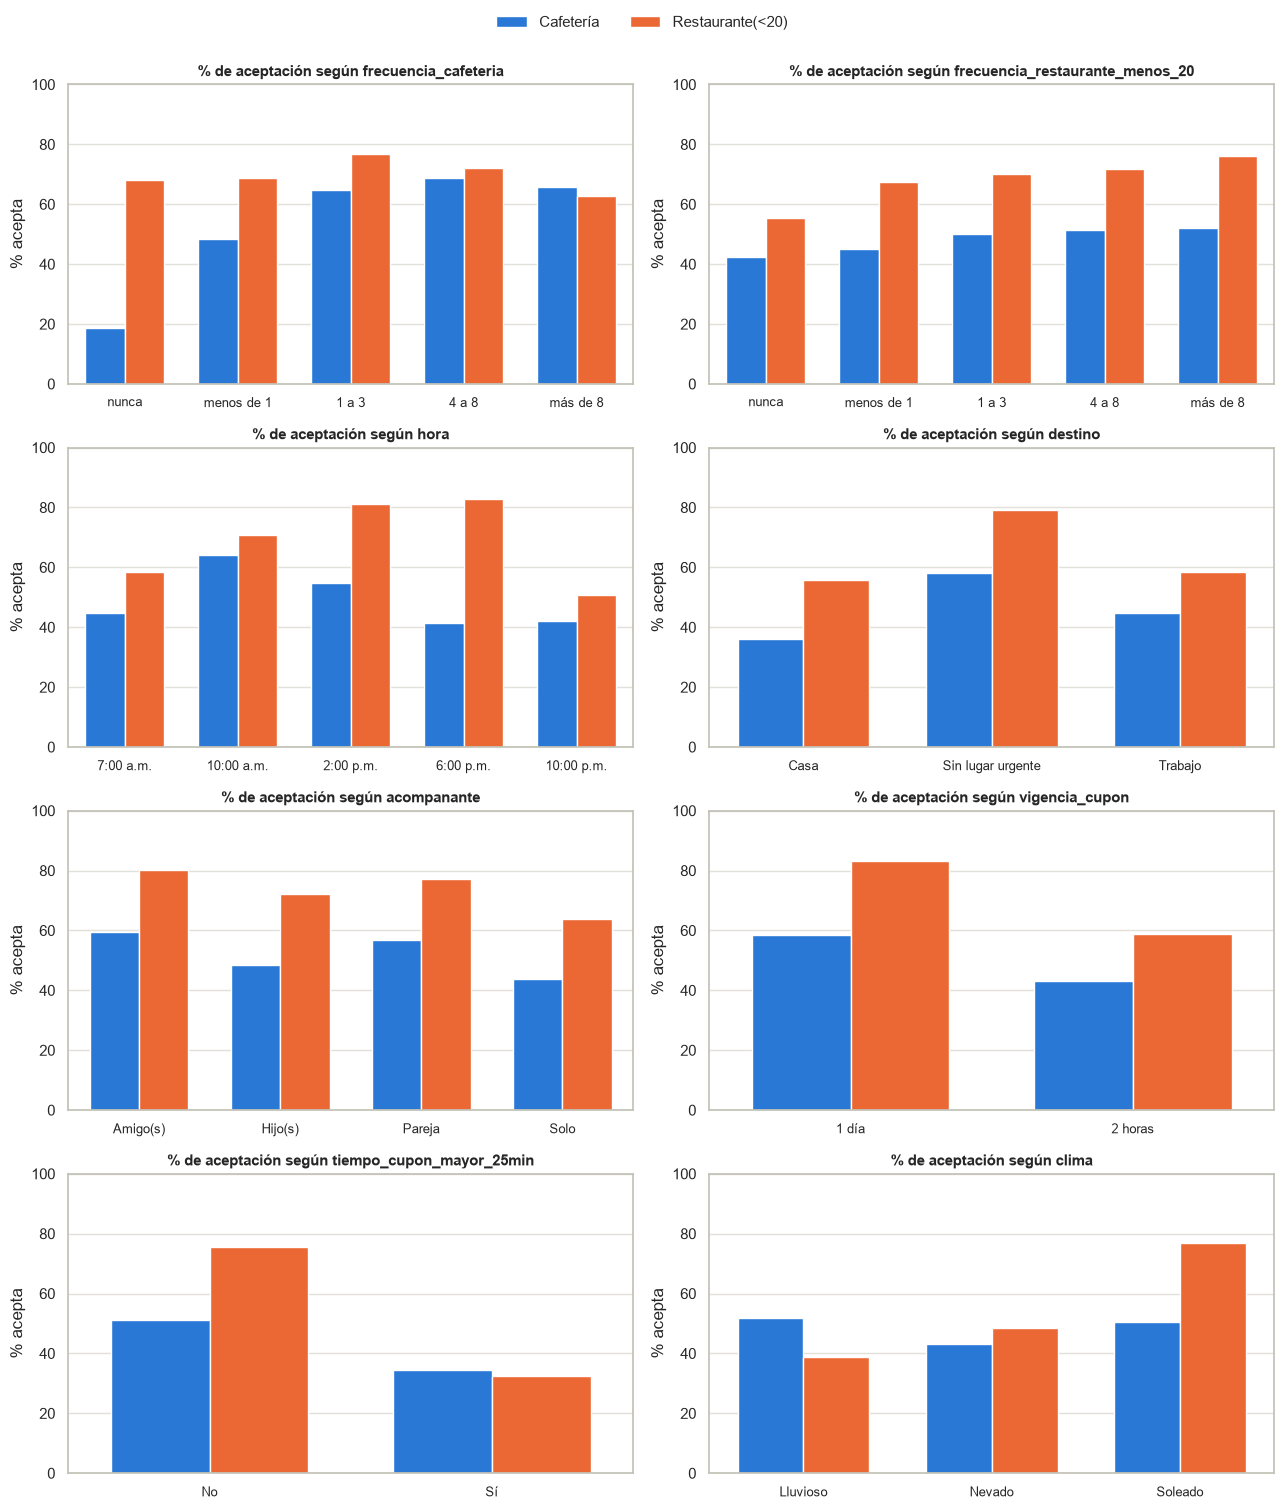

In [10]:
VARS_CLAVE = ["frecuencia_cafeteria", "frecuencia_restaurante_menos_20", "hora", "destino",
              "acompanante", "vigencia_cupon", "tiempo_cupon_mayor_25min", "clima"]
df_eda = df_eda.assign(acepta=(df_eda["acepta_cupon"] == "Sí") * 100)

fig, axes = plt.subplots(4, 2, figsize=(13, 15))
for ax, var in zip(axes.ravel(), VARS_CLAVE):
    orden = DOMINIOS[var] if var in ORDINAL_CATEGORIES else sorted(df_eda[var].dropna().unique())
    sns.barplot(data=df_eda, x=var, y="acepta", hue="cupon", order=orden, hue_order=CUPONES,
                palette=COLORES, errorbar=None, width=0.7, saturation=1, ax=ax)
    ax.set_title(f"% de aceptación según {var}")
    ax.set_xlabel("")
    ax.set_ylabel("% acepta")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", labelsize=9)
    ax.get_legend().remove()
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.01))
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

Lo que vemos en las gráficas (porcentajes calculados sobre los datos de cada subconjunto):

- **En Cafetería el hábito pesa muchísimo.** Entre quienes nunca van a cafeterías solo el 18.8% acepta el cupón, mientras que entre quienes van de 1 a 8 veces al mes la aceptación ronda el 65-69%. En Restaurante(&lt;20) el hábito equivalente (`frecuencia_restaurante_menos_20`) también ayuda, pero mucho menos: la aceptación pasa de 55.6% a 76.0%.
- **La hora no tiene un efecto lineal.** Para Cafetería el pico es a las 10:00 a.m. (64%) y en la tarde-noche cae a 41-42%. Para Restaurante(&lt;20) lo mejor es a las 2:00 y 6:00 p.m. (81-83%, hora de almuerzo y de comida) y lo peor a las 10:00 p.m. (50.6%). Esto le complica la vida a la regresión logística, que trata `hora` como ordinal y solo puede ajustar una tendencia que sube o baja.
- **Ir sin afán ayuda en los dos cupones.** Con destino "Sin lugar urgente" se acepta mucho más (58% en Cafetería y 79% en Restaurante(&lt;20)) que yendo a casa o al trabajo.
- **Yendo solo es cuando menos se acepta**, y con amigos cuando más.
- **La vigencia importa**, sobre todo en Restaurante(&lt;20): un cupón de 1 día se acepta en el 83% de los casos y uno de 2 horas en el 59%.
- **La distancia y el clima golpean fuerte a Restaurante(&lt;20).** Si el restaurante queda a más de 25 minutos la aceptación cae de 75.5% a 32.6%, y con lluvia o nieve baja a 39-49%, frente a 77% con sol. En Cafetería el clima casi no cambia nada.

### 3.8 Asociación entre variables (posible redundancia)

Como casi todas las variables son categóricas, en lugar de la correlación de Pearson usamos la V de Cramér, que va de 0 (no hay relación) a 1 (una variable determina por completo a la otra). La calculamos entre todas las variables para buscar redundancias y, más abajo, entre cada variable y `acepta_cupon` en cada subconjunto, para tener una primera idea (sin modelos) de qué está más relacionado con la aceptación.

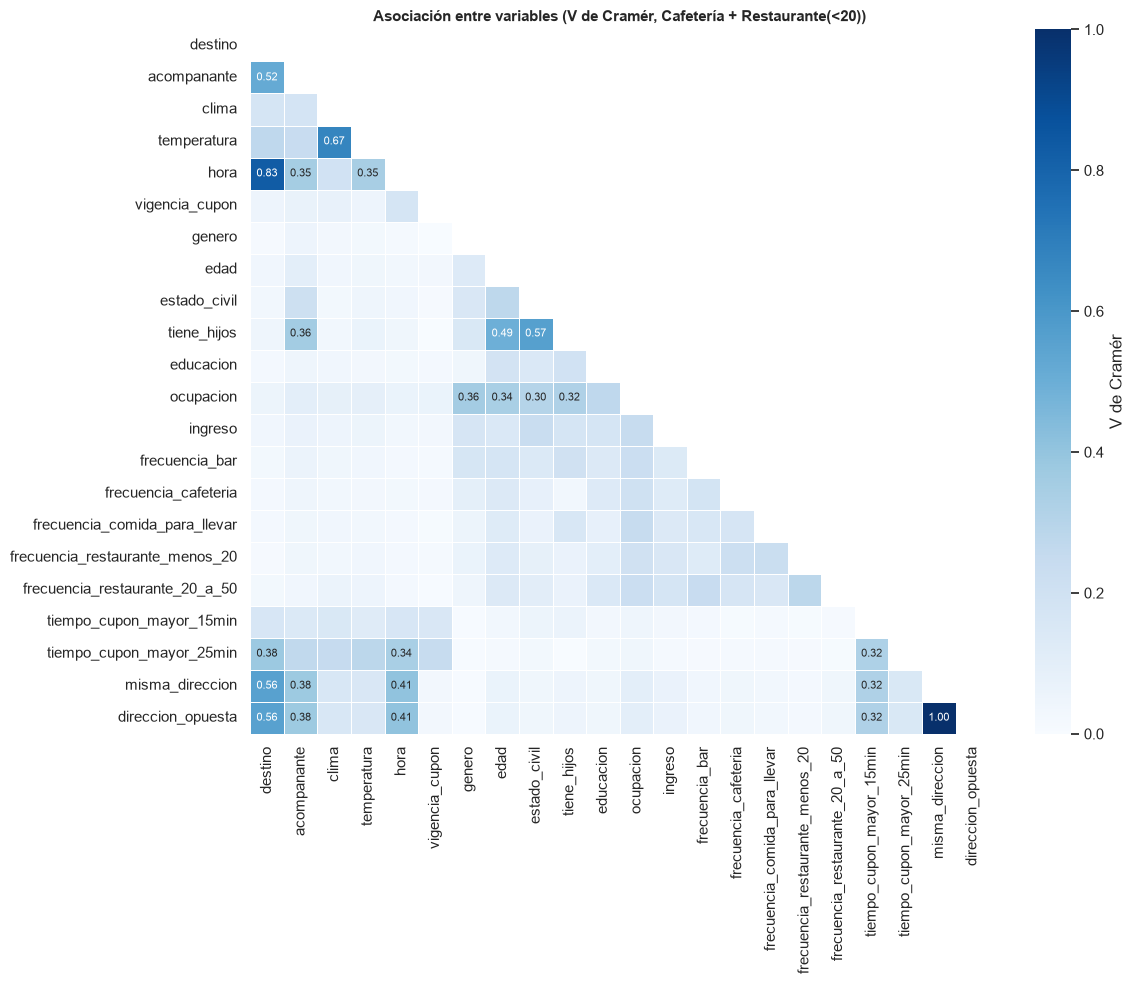

Pares más asociados:
misma_direccion  direccion_opuesta    1.000
destino          hora                 0.832
clima            temperatura          0.673
estado_civil     tiene_hijos          0.565
destino          direccion_opuesta    0.558
                 misma_direccion      0.558
                 acompanante          0.518
edad             tiene_hijos          0.494


In [11]:
def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    if min(tabla.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(tabla, correction=False)[0]
    return np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))

VARS_ASOC = [c for c in df.columns if c not in ["vehiculo", "cupon", "tiempo_cupon_mayor_5min", "acepta_cupon"]]
matriz_v = pd.DataFrame(1.0, index=VARS_ASOC, columns=VARS_ASOC)
for i, a in enumerate(VARS_ASOC):
    for b in VARS_ASOC[i + 1:]:
        matriz_v.loc[a, b] = matriz_v.loc[b, a] = cramers_v(df_eda[a], df_eda[b])

anotaciones = matriz_v.map(lambda v: f"{v:.2f}" if v >= 0.3 else "")
plt.figure(figsize=(12, 10))
sns.heatmap(matriz_v, mask=np.triu(np.ones_like(matriz_v, dtype=bool)), cmap="Blues", vmin=0, vmax=1,
            annot=anotaciones, fmt="", annot_kws={"size": 8}, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "V de Cramér"})
plt.grid(False)
plt.title("Asociación entre variables (V de Cramér, Cafetería + Restaurante(<20))")
plt.tight_layout()
plt.show()

pares = matriz_v.where(np.triu(np.ones_like(matriz_v, dtype=bool), k=1)).stack()
print("Pares más asociados:")
print(pares.sort_values(ascending=False).head(8).round(3).to_string())

En el heatmap nos llamó la atención que `tiempo_cupon_mayor_25min` esté asociada con `destino` (0.38) y con `hora` (0.34). Como en Restaurante(&lt;20) la distancia parecía tan determinante, revisamos en qué contexto aparecen los cupones "lejanos" (porcentaje de escenarios en cada categoría):

In [12]:
rest = subconjuntos["Restaurante(<20)"]
lejos = rest["tiempo_cupon_mayor_25min"] == "Sí"
contexto = pd.concat({
    var: pd.DataFrame({"Más de 25 min": rest.loc[lejos, var].value_counts(normalize=True),
                       "Hasta 25 min": rest.loc[~lejos, var].value_counts(normalize=True)})
    for var in ["clima", "hora", "destino", "acompanante", "vigencia_cupon"]
}).fillna(0).mul(100).round(1)
display(contexto)

print("% de aceptación en Restaurante(<20) según el clima:")
aceptacion_clima = rest.groupby([lejos.map({True: "Más de 25 min", False: "Hasta 25 min"}), "clima"])["acepta_cupon"]
print((aceptacion_clima.apply(lambda x: (x == "Sí").mean() * 100).unstack().round(1)).to_string())

Más de 25 min  Hasta 25 min
clima          Lluvioso                    28.1           3.4
               Nevado                      61.3           7.5
               Soleado                     10.6          89.1
hora           10:00 a.m.                   0.0          12.2
               10:00 p.m.                  28.7          15.2
               2:00 p.m.                    0.0          28.1
               6:00 p.m.                    9.0          29.0
               7:00 a.m.                   62.3          15.4
destino        Casa                        37.7          15.4
               Sin lugar urgente            0.0          69.2
               Trabajo                     62.3          15.4
acompanante    Amigo(s)                     0.0          33.3
               Hijo(s)                      0.0          10.8
               Pareja                       9.0           9.3
               Solo                        91.0          46.6
vigencia_cupon 1 día                       10.6          53.4
               2 horas                     89.4          46.6

% de aceptación en Restaurante(<20) según el clima:
clima                     Lluvioso  Nevado  Soleado
tiempo_cupon_mayor_25min                           
Hasta 25 min                  48.2    71.9     76.8
Más de 25 min                 29.9    25.8     78.8


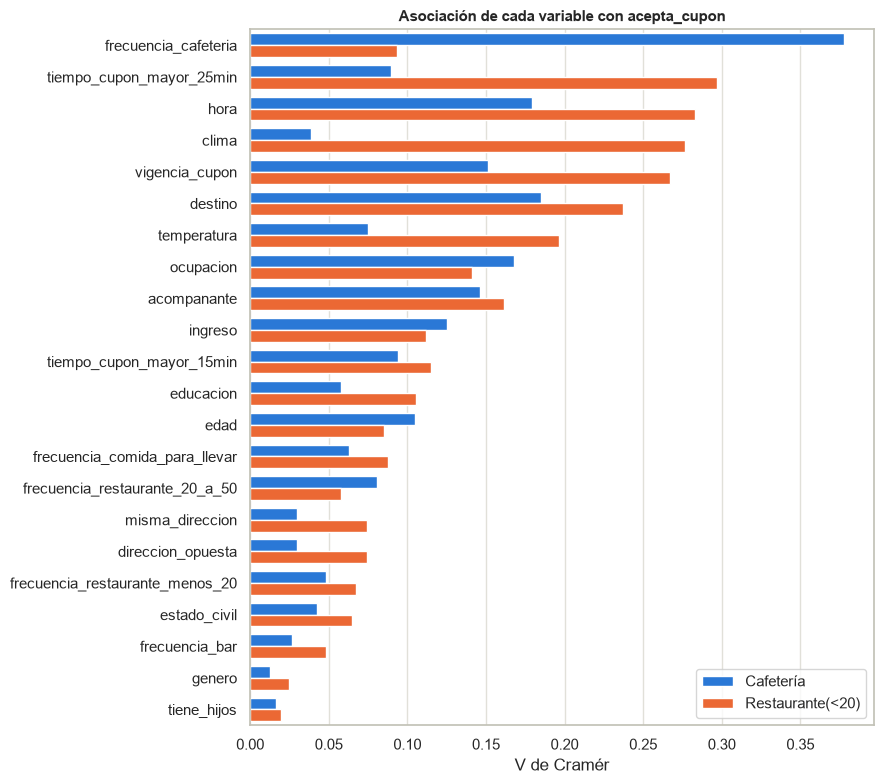

,Cafetería,Restaurante(<20)
frecuencia_cafeteria,0.378,0.093
tiempo_cupon_mayor_25min,0.089,0.297
hora,0.179,0.283
clima,0.039,0.277
vigencia_cupon,0.151,0.267
destino,0.185,0.237
temperatura,0.075,0.196
ocupacion,0.168,0.141
acompanante,0.146,0.161
ingreso,0.125,0.112


In [13]:
asociacion_objetivo = pd.DataFrame({
    cupon: {var: cramers_v(s[var], s["acepta_cupon"]) for var in VARS_ASOC}
    for cupon, s in subconjuntos.items()
})
asociacion_objetivo = asociacion_objetivo.loc[asociacion_objetivo.max(axis=1).sort_values(ascending=False).index]

datos_plot = asociacion_objetivo.reset_index(names="Variable").melt(
    id_vars="Variable", var_name="Cupón", value_name="V de Cramér")
plt.figure(figsize=(9, 8))
sns.barplot(data=datos_plot, y="Variable", x="V de Cramér", hue="Cupón", palette=COLORES, width=0.75, saturation=1)
plt.title("Asociación de cada variable con acepta_cupon")
plt.ylabel("")
plt.legend(title=None, loc="lower right")
plt.tight_layout()
plt.show()

asociacion_objetivo.round(3).head(10)

De estas salidas sacamos lo siguiente:

- La redundancia más clara es `misma_direccion` con `direccion_opuesta` (V = 1.00), lo que confirma que sobra una de las dos.
- `destino` y `hora` (V = 0.83) y `clima` y `temperatura` (V = 0.67) están muy asociadas por el diseño de la encuesta. No son copias exactas, entonces las dejamos, pero hay que tener cuidado al interpretar su importancia por separado.
- Entre las variables del perfil hay asociaciones esperables: `estado_civil` con `tiene_hijos` (0.57), `edad` con `tiene_hijos` (0.49) y `ocupacion` con género, edad y estado civil (0.30-0.36). Esto importa cuando hablemos de sesgo: aunque se quitara una variable sensible como la edad, otras (como la ocupación "Estudiante" o "Jubilado(a)") permiten adivinarla bastante bien.
- Los escenarios con el restaurante a más de 25 minutos son casi siempre con mal clima (89%: 61% con nieve y 28% con lluvia), a las 7:00 a.m. o a las 10:00 p.m., camino al trabajo o a la casa, yendo solo (91%) y con un cupón de 2 horas (89%). Es decir, "lejos" viene acompañado de casi todas las condiciones desfavorables al mismo tiempo. La tabla de aceptación por clima muestra algo curioso: con sol, los cupones lejanos se aceptan igual que los cercanos (78.8% vs 76.8%), mientras que con nieve la aceptación pasa de 71.9% a 25.8% cuando el restaurante queda lejos. La distancia pesa sobre todo cuando el clima es malo (aunque los lejanos con sol son pocos casos).

Sobre la relación con `acepta_cupon`:

- En **Cafetería**, `frecuencia_cafeteria` está muy por encima del resto (V = 0.38). La siguen de lejos `destino`, `hora`, `ocupacion` y `vigencia_cupon` (entre 0.15 y 0.19).
- En **Restaurante(&lt;20)** no hay una variable dominante. Las más asociadas son todas de contexto: `tiempo_cupon_mayor_25min`, `hora`, `clima`, `vigencia_cupon` y `destino` (entre 0.24 y 0.30).
- `genero` y `tiene_hijos` casi no tienen relación con la aceptación en ninguno de los dos cupones (V entre 0.01 y 0.03).

### 3.9 Resumen de hallazgos

1. Casi todas las variables son categóricas (nominales u ordinales); la única numérica, `temperatura`, solo toma tres valores.
2. **Completitud:** `vehiculo` está vacía en el 99% de los casos y las cinco frecuencias tienen menos de 2% de faltantes.
3. **Unicidad:** hay 7 duplicados exactos por subconjunto, y cada conductor aparece en varios escenarios (las filas no son independientes).
4. **Validez:** no hay valores fuera del diccionario en las variables que vamos a usar; hay algunos perfiles raros pero plausibles.
5. **Consistencia:** `direccion_opuesta` es el complemento exacto de `misma_direccion`, `tiempo_cupon_mayor_5min` es constante, y varias variables de contexto vienen amarradas por el diseño de la encuesta (destino con hora, clima con temperatura, distancia con clima y hora).
6. **Variable objetivo:** Cafetería está balanceada; Restaurante(&lt;20) tiene un desbalance moderado (70.7% Sí), con "No" como clase minoritaria.
7. La aceptación de Cafetería depende sobre todo del hábito de ir a cafeterías; la de Restaurante(&lt;20), del contexto del viaje (distancia, clima, hora, vigencia y destino).

## 4. Actividad 2: Limpieza y preparación de los datos

Con base en la exploración, estas son las decisiones que tomamos. Todo se aplica igual a los dos subconjuntos:

| Hallazgo | Decisión | Por qué |
|---|---|---|
| `vehiculo` vacía en el 99% | Eliminar la columna | No se puede imputar algo que casi nunca se observó |
| `tiempo_cupon_mayor_5min` constante | Eliminar | No distingue entre los que aceptan y los que no |
| `direccion_opuesta` es el opuesto exacto de `misma_direccion` | Eliminar `direccion_opuesta` | Información repetida; en la regresión logística además genera colinealidad perfecta |
| `cupon` constante dentro de cada subconjunto | Eliminar | Después de filtrar ya no aporta nada |
| 7 duplicados exactos por subconjunto | Eliminar | Evita que una misma fila quede en train y en test |
| Mismas variables con distinta respuesta | Conservar | No hay forma de saber cuál respuesta es la buena |
| Perfiles raros e inconsistencias entre `acompanante` y `tiene_hijos` | Conservar | Son pocos, plausibles y no se pueden verificar |
| 0.8-1.8% de faltantes en las variables de frecuencia | Imputar con la moda, dentro del pipeline | Borrar las filas costaría casi 5% de los datos; dentro del pipeline la moda se calcula solo con train |
| Variables ordinales (`hora`, `edad`, `educacion`, `ingreso` y las cinco frecuencias) | `OrdinalEncoder` con el orden del diccionario | Conserva el orden natural (nunca &lt; menos de 1 &lt; 1 a 3...) sin multiplicar columnas |
| Variables Sí/No | Codificar como 0/1 | Para dos niveles no hace falta crear dos columnas |
| Variables nominales (`destino`, `acompanante`, `clima`, `vigencia_cupon`, `genero`, `estado_civil`, `ocupacion`) | `OneHotEncoder(handle_unknown="ignore")` | No tienen orden; `ignore` evita que una categoría nueva rompa el pipeline |
| `temperatura` | Dejarla numérica, con imputación por mediana de respaldo | Solo tiene tres valores y ningún faltante |
| Escalas muy distintas (temperatura de 30 a 80, códigos de 0 a 8, dummies 0/1) | `MinMaxScaler` a [0, 1], solo para la regresión logística | La regularización penaliza todos los coeficientes por igual, así que las variables deben estar en escalas comparables; además así los coeficientes se pueden comparar entre sí. A los árboles la escala no les afecta |

La variable objetivo queda como 1 = "Sí" (acepta) y 0 = "No". Todo el preprocesamiento va dentro de un `ColumnTransformer` que hace parte de cada pipeline. Así, en la validación cruzada, la imputación y la codificación se ajustan solo con los datos de entrenamiento de cada fold, y no hay fuga de información hacia la validación ni hacia el test.

In [14]:
COLS_A_ELIMINAR = ["vehiculo", "tiempo_cupon_mayor_5min", "direccion_opuesta", "cupon"]


def clean_subset(df_subset: pd.DataFrame, has_target: bool = True) -> pd.DataFrame:
    # Misma limpieza para cualquier subconjunto de cupón, etiquetado o no
    d = df_subset.drop(columns=COLS_A_ELIMINAR, errors="ignore")
    if has_target:
        d = d.drop_duplicates()
        d["acepta_cupon"] = d["acepta_cupon"].map({"Sí": 1, "No": 0})
    return d.reset_index(drop=True)


ORDINAL_COLS = list(ORDINAL_CATEGORIES.keys())
BINARY_COLS = ["tiene_hijos", "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min", "misma_direccion"]
NOMINAL_COLS = ["destino", "acompanante", "clima", "vigencia_cupon", "genero", "estado_civil", "ocupacion"]
NUMERIC_COLS = ["temperatura"]


def build_preprocessor(escalar: bool = False, excluir: tuple = ()) -> ColumnTransformer:
    # escalar=True deja todo en [0, 1]; solo lo usamos para la regresión logística.
    # excluir sirve para el experimento sin variables demográficas de la sección 11.
    ordinales = [c for c in ORDINAL_COLS if c not in excluir]
    binarias = [c for c in BINARY_COLS if c not in excluir]
    nominales = [c for c in NOMINAL_COLS if c not in excluir]

    ordinal_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(categories=[ORDINAL_CATEGORIES[c] for c in ordinales])),
    ]
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if escalar:
        ordinal_steps.append(("scaler", MinMaxScaler()))
        numeric_steps.append(("scaler", MinMaxScaler()))

    binary_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(categories=[["No", "Sí"]] * len(binarias))),
    ])
    nominal_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("ord", Pipeline(ordinal_steps), ordinales),
        ("bin", binary_pipe, binarias),
        ("nom", nominal_pipe, nominales),
        ("num", Pipeline(numeric_steps), NUMERIC_COLS),
    ], verbose_feature_names_out=False)

In [15]:
df_cafeteria = clean_subset(subconjuntos["Cafetería"])
df_restaurante = clean_subset(subconjuntos["Restaurante(<20)"])

for nombre, d in [("Cafetería", df_cafeteria), ("Restaurante(<20)", df_restaurante)]:
    X = d.drop(columns="acepta_cupon")
    X_transformada = build_preprocessor().fit_transform(X)
    print(f"{nombre}: {len(d)} filas, {X.shape[1]} variables -> {X_transformada.shape[1]} columnas al codificar | "
          f"duplicados: {d.duplicated().sum()} | NaN tras imputar: {int(np.isnan(X_transformada).sum())} | "
          f"% acepta: {d['acepta_cupon'].mean():.1%}")

Cafetería: 3979 filas, 21 variables -> 58 columnas al codificar | duplicados: 0 | NaN tras imputar: 0 | % acepta: 49.8%
Restaurante(<20): 2769 filas, 21 variables -> 58 columnas al codificar | duplicados: 0 | NaN tras imputar: 0 | % acepta: 70.7%


Después de la limpieza quedan 3979 escenarios de Cafetería y 2769 de Restaurante(&lt;20), cada uno con 21 variables que se convierten en 58 columnas al codificar. Ya no hay duplicados ni vacíos después de imputar, y como el `OrdinalEncoder` tiene las categorías fijas, si llegara un valor fuera del dominio el pipeline fallaría en vez de seguir en silencio. La proporción de "Sí" prácticamente no cambió con la limpieza (49.8% y 70.7%).

## 5. Configuración común del modelado

Antes de entrenar dejamos fija la forma de evaluar, igual para los dos cupones:

- **Partición:** 80% para entrenamiento y 20% para test, estratificada por `acepta_cupon` para que ambas partes tengan la misma proporción de clases. El test solo se usa al final, para reportar resultados.
- **Validación cruzada:** `StratifiedKFold` de 5 folds sobre el entrenamiento, dentro de `GridSearchCV`.
- **Métrica para escoger hiperparámetros:** F1 de la clase "Sí" (acepta). Es la métrica con la que se comparan los modelos y equilibra precisión y recall. Como complemento guardamos también la precisión y el recall de la clase "No" y el F1 macro, que en Restaurante(&lt;20) son los que delatan si el modelo está ignorando a la clase minoritaria.
- **Grillas:**
    - *Regresión logística:* tipo de regularización (L1, L2 y elastic net), solver (`lbfgs`, `liblinear`, `saga`) y fuerza de regularización `C`. No todas las combinaciones existen (`lbfgs` solo funciona con L2 y elastic net solo con `saga`), por eso la grilla va en tres bloques.
    - *Árbol de decisión:* profundidad máxima, mínimo de muestras por hoja y criterio de división (gini o entropía).
    - *Random Forest:* número de árboles, profundidad máxima, mínimo de muestras por hoja y `max_features` (cuántas variables se consideran en cada división). Este último no lo pedía la guía, pero es el que controla qué tan distintos son los árboles entre sí y suele importar.

Las funciones de abajo son para no repetir el mismo código seis veces: `crear_pipeline` arma el pipeline (con o sin SMOTE), `evaluar_busqueda` corre la búsqueda y reporta el desempeño en test, y `resumen_busqueda` muestra el mejor F1 de validación para cada par de hiperparámetros, que sirve para ver qué tanto importa cada uno.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# En scikit-learn 1.8+ 'penalty' sale como deprecado (recomiendan usar l1_ratio), pero sigue
# funcionando igual y deja explícito el tipo de regularización, que es justo lo que queremos comparar.
PARAM_GRID_LR = [
    {"model__penalty": ["l2"], "model__solver": ["lbfgs", "liblinear", "saga"], "model__C": [0.01, 0.1, 1, 10]},
    {"model__penalty": ["l1"], "model__solver": ["liblinear", "saga"], "model__C": [0.01, 0.1, 1, 10]},
    {"model__penalty": ["elasticnet"], "model__solver": ["saga"], "model__l1_ratio": [0.5],
     "model__C": [0.01, 0.1, 1, 10]},
]
PARAM_GRID_DT = {
    "model__max_depth": [3, 5, 8, 12, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__criterion": ["gini", "entropy"],
}
PARAM_GRID_RF = {
    "model__n_estimators": [100, 200, 400],
    "model__max_depth": [5, 10, 20, None],
    "model__min_samples_leaf": [1, 5, 10],
    "model__max_features": ["sqrt", 0.3, 0.5],
}


def crear_pipeline(modelo, escalar=False, smote=False):
    pasos = [("preprocessor", build_preprocessor(escalar=escalar))]
    if smote:
        # imblearn aplica SMOTE solo en fit, o sea solo sobre el train de cada fold
        return ImbPipeline(pasos + [("smote", SMOTE(random_state=RANDOM_STATE)), ("model", modelo)])
    return Pipeline(pasos + [("model", modelo)])


def evaluar_busqueda(nombre, busqueda, X_train, y_train, X_test, y_test):
    busqueda.fit(X_train, y_train)
    pred = busqueda.best_estimator_.predict(X_test)
    params = {k.replace("model__", ""): v for k, v in busqueda.best_params_.items()}
    print(f"Mejores hiperparámetros: {params}")
    print(f"F1 promedio en validación cruzada: {busqueda.best_score_:.3f}\n")
    print("Desempeño en test:")
    print(classification_report(y_test, pred, digits=3, target_names=["No acepta", "Acepta"]))
    return {
        "Modelo": nombre,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Precision clase No": precision_score(y_test, pred, pos_label=0),
        "Recall clase No": recall_score(y_test, pred, pos_label=0),
        "F1 macro": f1_score(y_test, pred, average="macro"),
        "F1 CV": busqueda.best_score_,
        "Hiperparámetros": ", ".join(f"{k}={v}" for k, v in params.items()),
    }


def _orden(valor):
    try:
        return (0, float(valor))
    except ValueError:
        return (1, valor)


def resumen_busqueda(busqueda, filas, columnas):
    # Mejor F1 de CV para cada par de hiperparámetros (el máximo sobre los demás)
    res = pd.DataFrame(busqueda.cv_results_)
    tabla = res.pivot_table(index=res[f"param_model__{filas}"].map(str),
                            columns=res[f"param_model__{columnas}"].map(str),
                            values="mean_test_score", aggfunc="max")
    tabla = tabla.loc[sorted(tabla.index, key=_orden), sorted(tabla.columns, key=_orden)]
    return tabla.rename_axis(index=filas, columns=columnas).round(3)


def matrices_confusion(modelos, X_test, y_test, titulo):
    fig, axes = plt.subplots(1, len(modelos), figsize=(4.2 * len(modelos), 3.8))
    for ax, (nombre, modelo) in zip(np.atleast_1d(axes), modelos.items()):
        ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, display_labels=["No", "Sí"],
                                              cmap="Blues", colorbar=False, ax=ax)
        ax.set_title(nombre)
        ax.set_xlabel("Predicho")
        ax.set_ylabel("Real")
        ax.grid(False)
    fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout()
    plt.show()

## 6. Modelos para Cafetería (actividades 3, 4 y 5)

In [17]:
X_cafe = df_cafeteria.drop(columns=["acepta_cupon"])
y_cafe = df_cafeteria["acepta_cupon"]

X_train_cafe, X_test_cafe, y_train_cafe, y_test_cafe = train_test_split(
    X_cafe, y_cafe, test_size=0.2, random_state=RANDOM_STATE, stratify=y_cafe
)
print(f"Entrenamiento: {X_train_cafe.shape} | Test: {X_test_cafe.shape}")
print(f"% acepta en train: {y_train_cafe.mean():.1%} | en test: {y_test_cafe.mean():.1%}")

resultados_cafe = []

Entrenamiento: (3183, 21) | Test: (796, 21)
% acepta en train: 49.8% | en test: 49.9%


### 6.1 Actividad 3: Regresión logística (Cafetería)

El pipeline es el preprocesador (con escalamiento a [0, 1]) seguido de `LogisticRegression`. La búsqueda recorre 24 combinaciones de regularización, solver y `C`.

In [18]:
gs_lr_cafe = GridSearchCV(
    crear_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), escalar=True),
    PARAM_GRID_LR, scoring="f1", cv=cv, n_jobs=-1,
)
resultados_cafe.append(evaluar_busqueda("Regresión logística", gs_lr_cafe,
                                        X_train_cafe, y_train_cafe, X_test_cafe, y_test_cafe))
resumen_busqueda(gs_lr_cafe, "penalty", "solver")

Mejores hiperparámetros: {'C': 1, 'penalty': 'l1', 'solver': 'saga'}
F1 promedio en validación cruzada: 0.707

Desempeño en test:
              precision    recall  f1-score   support

   No acepta      0.699     0.682     0.690       399
      Acepta      0.688     0.705     0.697       397

    accuracy                          0.693       796
   macro avg      0.694     0.693     0.693       796
weighted avg      0.694     0.693     0.693       796



solver,lbfgs,liblinear,saga
penalty,,,
elasticnet,NaN,NaN,0.706
l1,NaN,0.706,0.707
l2,0.706,0.707,0.706


La mejor combinación fue regularización L1 con `saga` y `C = 1`: F1 de 0.707 en validación y de 0.697 en test. Lo más llamativo de la tabla es que todas las combinaciones de penalización y solver quedan entre 0.706 y 0.707, o sea que el tipo de regularización casi no cambia nada (`NaN` son las combinaciones que no existen). Para nosotros eso indica que el límite no está en cómo se regulariza sino en el modelo mismo: una regresión logística solo puede sumar efectos y asume que las variables ordinales empujan siempre en la misma dirección, y ya vimos que, por ejemplo, la hora no se comporta así. El modelo se equivoca parecido en las dos clases (recall de 0.705 en "Sí" y de 0.682 en "No"), algo normal con clases balanceadas.

### 6.2 Actividad 4: Árbol de decisión (Cafetería)

Exploramos la profundidad máxima (3, 5, 8, 12 o sin límite), el mínimo de muestras por hoja (1, 5, 10 o 20) y el criterio de división (gini o entropía), 40 combinaciones en total.

In [19]:
gs_dt_cafe = GridSearchCV(
    crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    PARAM_GRID_DT, scoring="f1", cv=cv, n_jobs=-1,
)
resultados_cafe.append(evaluar_busqueda("Árbol de decisión", gs_dt_cafe,
                                        X_train_cafe, y_train_cafe, X_test_cafe, y_test_cafe))
resumen_busqueda(gs_dt_cafe, "max_depth", "min_samples_leaf")

Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 5}
F1 promedio en validación cruzada: 0.711

Desempeño en test:
              precision    recall  f1-score   support

   No acepta      0.689     0.672     0.680       399
      Acepta      0.678     0.695     0.687       397

    accuracy                          0.683       796
   macro avg      0.684     0.683     0.683       796
weighted avg      0.684     0.683     0.683       796



min_samples_leaf,1,5,10,20
max_depth,,,,
3,0.703,0.703,0.703,0.703
5,0.711,0.711,0.710,0.710
8,0.693,0.695,0.685,0.684
12,0.687,0.681,0.670,0.680
None,0.686,0.678,0.667,0.680


El mejor árbol usa entropía, profundidad 5 y mínimo 5 muestras por hoja (F1 de 0.711 en validación y de 0.687 en test). La tabla muestra bien el balance entre sesgo y varianza: con profundidad 3 el árbol se queda corto (0.703), con 5 llega a su mejor punto y de ahí en adelante empeora porque empieza a memorizar el entrenamiento (con profundidad 12 o sin límite baja a 0.67-0.69). Un solo árbol termina rindiendo parecido a la regresión logística, aunque tiene la ventaja de que sus reglas se pueden leer (lo aprovechamos en la sección 10).

### 6.3 Actividad 5: Random Forest (Cafetería)

La búsqueda incluye el número de árboles (100, 200 o 400), la profundidad máxima (5, 10, 20 o sin límite), el mínimo de muestras por hoja (1, 5 o 10) y `max_features` (raíz cuadrada del número de columnas, 30% o 50%), 108 combinaciones. Las dos tablas resumen muestran el mejor F1 de validación según profundidad y tamaño de hoja, y según número de árboles y `max_features`.

In [20]:
gs_rf_cafe = GridSearchCV(
    crear_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)),
    PARAM_GRID_RF, scoring="f1", cv=cv, n_jobs=-1,
)
resultados_cafe.append(evaluar_busqueda("Random Forest", gs_rf_cafe,
                                        X_train_cafe, y_train_cafe, X_test_cafe, y_test_cafe))
display(resumen_busqueda(gs_rf_cafe, "max_depth", "min_samples_leaf"))
resumen_busqueda(gs_rf_cafe, "n_estimators", "max_features")

Mejores hiperparámetros: {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 200}
F1 promedio en validación cruzada: 0.760

Desempeño en test:
              precision    recall  f1-score   support

   No acepta      0.776     0.779     0.777       399
      Acepta      0.777     0.773     0.775       397

    accuracy                          0.776       796
   macro avg      0.776     0.776     0.776       796
weighted avg      0.776     0.776     0.776       796



min_samples_leaf,1,5,10
max_depth,,,
5,0.729,0.729,0.728
10,0.752,0.738,0.733
20,0.758,0.739,0.733
None,0.760,0.739,0.733


max_features,0.3,0.5,sqrt
n_estimators,,,
100,0.759,0.752,0.751
200,0.760,0.755,0.756
400,0.757,0.755,0.759


Random Forest es claramente el mejor de los tres en Cafetería: F1 de 0.760 en validación y de 0.775 en test, unos 8 puntos por encima de la regresión logística y del árbol. La mejor configuración usa árboles sin límite de profundidad, hojas de una sola muestra, 200 árboles y 30% de las variables en cada división.

A diferencia del árbol individual, aquí dejar crecer los árboles sí funciona: cada árbol por separado se sobreajusta, pero al promediar 200 árboles distintos esa varianza se compensa. Las tablas muestran que lo que más mueve el resultado es la complejidad de cada árbol (de 0.729 con profundidad 5 a 0.760 sin límite, y con hojas de 5 o 10 muestras se queda en 0.73-0.74), mientras que el número de árboles y `max_features` cambian el resultado muy poco (todas esas combinaciones quedan entre 0.751 y 0.760). El modelo además es igual de bueno con las dos clases (recall de 0.773 en "Sí" y de 0.779 en "No").

### 6.4 Resumen de Cafetería

,Precision,Recall,F1,Precision clase No,Recall clase No,F1 macro,F1 CV
Modelo,,,,,,,
Regresión logística,0.688,0.705,0.697,0.699,0.682,0.693,0.707
Árbol de decisión,0.678,0.695,0.687,0.689,0.672,0.683,0.711
Random Forest,0.777,0.773,0.775,0.776,0.779,0.776,0.760


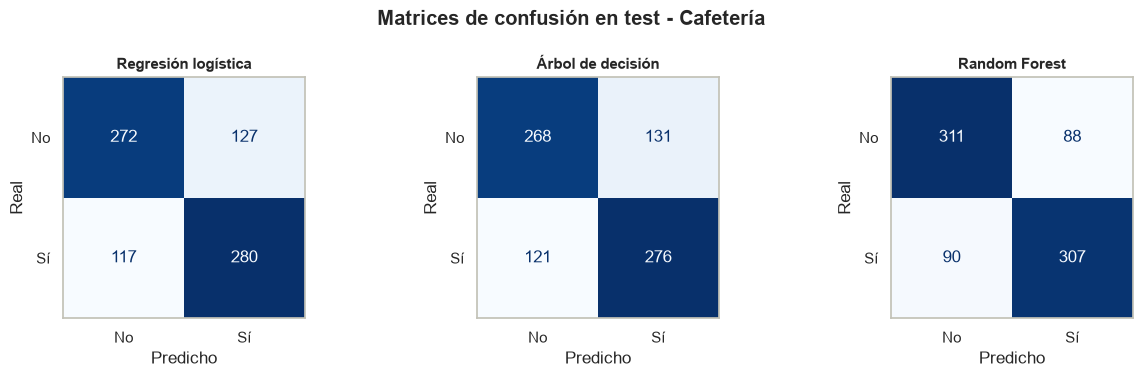

In [21]:
df_resultados_cafe = pd.DataFrame(resultados_cafe).set_index("Modelo")
display(df_resultados_cafe.drop(columns="Hiperparámetros").round(3))

busquedas_cafe = {"Regresión logística": gs_lr_cafe, "Árbol de decisión": gs_dt_cafe, "Random Forest": gs_rf_cafe}
matrices_confusion({n: b.best_estimator_ for n, b in busquedas_cafe.items()}, X_test_cafe, y_test_cafe,
                   "Matrices de confusión en test - Cafetería")

Las matrices de confusión dicen lo mismo que la tabla: los tres modelos reparten sus errores de forma pareja entre falsos positivos y falsos negativos, pero Random Forest comete bastantes menos de ambos tipos. Para Cafetería el ganador es Random Forest sin mucha discusión.

## 7. Modelos para Restaurante(&lt;20) (actividades 3, 4 y 5)

Seguimos exactamente el mismo procedimiento que en Cafetería: misma limpieza, mismo preprocesamiento, mismas grillas y misma métrica. La partición estratificada mantiene la proporción de 70.7% de "Sí" tanto en entrenamiento como en test.

In [22]:
X_rest = df_restaurante.drop(columns=["acepta_cupon"])
y_rest = df_restaurante["acepta_cupon"]

X_train_rest, X_test_rest, y_train_rest, y_test_rest = train_test_split(
    X_rest, y_rest, test_size=0.2, random_state=RANDOM_STATE, stratify=y_rest
)
print(f"Entrenamiento: {X_train_rest.shape} | Test: {X_test_rest.shape}")
print(f"% acepta en train: {y_train_rest.mean():.1%} | en test: {y_test_rest.mean():.1%}")

resultados_rest = []

Entrenamiento: (2215, 21) | Test: (554, 21)
% acepta en train: 70.7% | en test: 70.8%


### 7.1 Actividad 3: Regresión logística (Restaurante(&lt;20))

In [23]:
gs_lr_rest = GridSearchCV(
    crear_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), escalar=True),
    PARAM_GRID_LR, scoring="f1", cv=cv, n_jobs=-1,
)
resultados_rest.append(evaluar_busqueda("Regresión logística", gs_lr_rest,
                                        X_train_rest, y_train_rest, X_test_rest, y_test_rest))
resumen_busqueda(gs_lr_rest, "penalty", "solver")

Mejores hiperparámetros: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
F1 promedio en validación cruzada: 0.848

Desempeño en test:
              precision    recall  f1-score   support

   No acepta      0.655     0.352     0.458       162
      Acepta      0.775     0.923     0.843       392

    accuracy                          0.756       554
   macro avg      0.715     0.638     0.650       554
weighted avg      0.740     0.756     0.730       554



solver,lbfgs,liblinear,saga
penalty,,,
elasticnet,NaN,NaN,0.847
l1,NaN,0.846,0.846
l2,0.847,0.848,0.847


La mejor regresión logística usa L2 con `liblinear` y `C = 0.1`, una regularización más fuerte que en Cafetería. De nuevo la penalización y el solver casi no cambian el resultado (todo entre 0.846 y 0.848 en validación). Su F1 en test es 0.843, que a primera vista parece mejor que en Cafetería, pero el reporte cuenta otra historia: el recall de la clase "No" es apenas 0.352. O sea, de cada 100 conductores que no iban a aceptar, el modelo solo reconoce a 35; al resto le mandaría el cupón igual. El F1 alto viene sobre todo de que la mayoría de casos son "Sí".

### 7.2 Actividad 4: Árbol de decisión (Restaurante(&lt;20))

In [24]:
gs_dt_rest = GridSearchCV(
    crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    PARAM_GRID_DT, scoring="f1", cv=cv, n_jobs=-1,
)
resultados_rest.append(evaluar_busqueda("Árbol de decisión", gs_dt_rest,
                                        X_train_rest, y_train_rest, X_test_rest, y_test_rest))
resumen_busqueda(gs_dt_rest, "max_depth", "min_samples_leaf")

Mejores hiperparámetros: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 10}
F1 promedio en validación cruzada: 0.843

Desempeño en test:
              precision    recall  f1-score   support

   No acepta      0.633     0.383     0.477       162
      Acepta      0.781     0.908     0.840       392

    accuracy                          0.755       554
   macro avg      0.707     0.645     0.658       554
weighted avg      0.737     0.755     0.734       554



min_samples_leaf,1,5,10,20
max_depth,,,,
3,0.841,0.842,0.843,0.839
5,0.836,0.836,0.836,0.842
8,0.823,0.827,0.827,0.841
12,0.801,0.799,0.811,0.840
None,0.777,0.794,0.810,0.840


El mejor árbol es poco profundo (profundidad 3, gini y mínimo 10 muestras por hoja), con F1 de 0.840 en test y recall de "No" de 0.383. A diferencia de Cafetería, aquí los árboles profundos empeoran rápido (con profundidad 12 o sin límite y hojas de una muestra baja hasta 0.78-0.80), lo que sugiere que con menos datos y una clase minoritaria pequeña el árbol se sobreajusta con más facilidad. Los árboles profundos solo funcionan cuando las hojas son grandes (20 muestras), que es otra forma de regularizarlos.

### 7.3 Actividad 5: Random Forest (Restaurante(&lt;20))

In [25]:
gs_rf_rest = GridSearchCV(
    crear_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)),
    PARAM_GRID_RF, scoring="f1", cv=cv, n_jobs=-1,
)
resultados_rest.append(evaluar_busqueda("Random Forest", gs_rf_rest,
                                        X_train_rest, y_train_rest, X_test_rest, y_test_rest))
display(resumen_busqueda(gs_rf_rest, "max_depth", "min_samples_leaf"))
resumen_busqueda(gs_rf_rest, "n_estimators", "max_features")

Mejores hiperparámetros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 400}
F1 promedio en validación cruzada: 0.855

Desempeño en test:
              precision    recall  f1-score   support

   No acepta      0.705     0.414     0.521       162
      Acepta      0.793     0.929     0.855       392

    accuracy                          0.778       554
   macro avg      0.749     0.671     0.688       554
weighted avg      0.767     0.778     0.758       554



min_samples_leaf,1,5,10
max_depth,,,
5,0.849,0.848,0.849
10,0.855,0.849,0.849
20,0.853,0.850,0.850
None,0.855,0.850,0.850


max_features,0.3,0.5,sqrt
n_estimators,,,
100,0.854,0.850,0.853
200,0.853,0.854,0.854
400,0.855,0.854,0.855


Random Forest vuelve a ser el mejor: F1 de 0.855 tanto en validación como en test, con la mejor precisión (0.793), el mejor recall (0.929) y también el mejor recall de "No" (0.414) de los tres. La configuración ganadora usa árboles sin límite de profundidad, hojas de una muestra, `max_features` igual a la raíz cuadrada y 400 árboles. Eso sí, en Restaurante(&lt;20) casi todas las configuraciones del bosque quedan entre 0.848 y 0.855 en validación, y la ventaja sobre los otros modelos es mucho menor que en Cafetería (1-1.5 puntos de F1). El problema de fondo sigue ahí: el modelo identifica menos de la mitad de los rechazos.

### 7.4 Resumen de Restaurante(&lt;20)

,Precision,Recall,F1,Precision clase No,Recall clase No,F1 macro,F1 CV
Modelo,,,,,,,
Regresión logística,0.775,0.923,0.843,0.655,0.352,0.650,0.848
Árbol de decisión,0.781,0.908,0.840,0.633,0.383,0.658,0.843
Random Forest,0.793,0.929,0.855,0.705,0.414,0.688,0.855


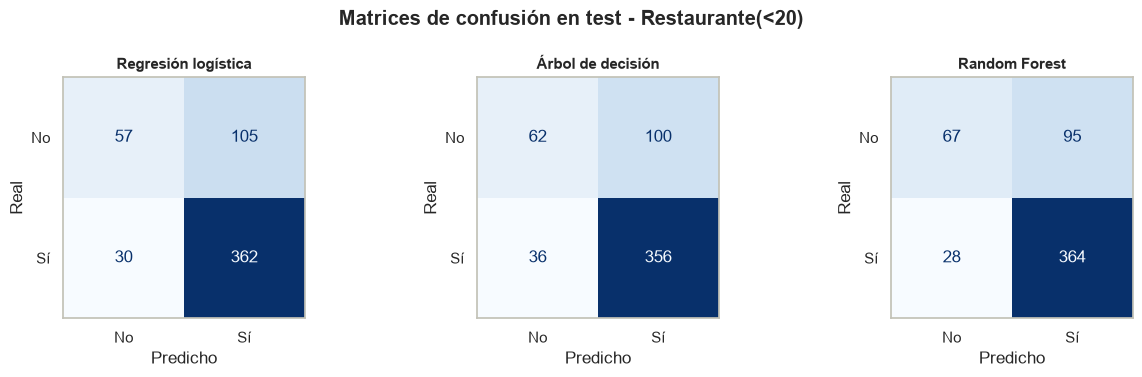

In [26]:
df_resultados_rest = pd.DataFrame(resultados_rest).set_index("Modelo")
display(df_resultados_rest.drop(columns="Hiperparámetros").round(3))

busquedas_rest = {"Regresión logística": gs_lr_rest, "Árbol de decisión": gs_dt_rest, "Random Forest": gs_rf_rest}
matrices_confusion({n: b.best_estimator_ for n, b in busquedas_rest.items()}, X_test_rest, y_test_rest,
                   "Matrices de confusión en test - Restaurante(<20)")

Las matrices de confusión dejan ver el sesgo hacia la clase mayoritaria: los tres modelos aciertan casi todos los "Sí", pero confunden la mayoría de los "No" con "Sí" (por ejemplo, Random Forest clasifica bien solo 67 de los 162 "No" del test). Es el efecto típico del desbalance, y es lo que vamos a intentar corregir con SMOTE en la siguiente sección.

## 8. Actividad 6: ¿Ayuda balancear las clases en Restaurante(&lt;20)?

**¿Por qué el desbalance podría afectar?** Con 70.7% de "Sí", los modelos aprenden que decir "Sí" casi siempre sale bien. Así minimizan el error global y logran un F1 alto en la clase positiva, pero a costa de la clase "No". Ya lo vimos: el recall de "No" está entre 0.35 y 0.41. Para Ruta Alpes eso significa que más de la mitad de los conductores que no van a aceptar el cupón igual lo reciben, que es justo la "molestia" que la empresa quiere reducir.

**¿Qué hace SMOTE?** Genera ejemplos sintéticos de la clase minoritaria interpolando entre cada ejemplo "No" y sus vecinos más cercanos, hasta igualar las clases. Lo aplicamos con un pipeline de `imbalanced-learn`, ubicado después del preprocesamiento y antes del modelo. La clave es que ese pipeline solo aplica SMOTE cuando se llama a `fit`: dentro de `GridSearchCV` el sobremuestreo toca únicamente el entrenamiento de cada fold, nunca el fold de validación ni el test. Si se hiciera SMOTE antes de partir los datos, habría puntos sintéticos construidos con filas del test dentro del entrenamiento, y la comparación quedaría inflada.

Para que la comparación sea justa repetimos la búsqueda de los tres algoritmos con las mismas grillas, los mismos folds, la misma métrica y el mismo test. La única diferencia es el paso de SMOTE.

Un detalle a tener en cuenta: casi todas nuestras variables son categóricas y SMOTE interpola sobre las columnas ya codificadas, así que crea conductores "intermedios" (por ejemplo, con 0.4 en una dummy de ocupación) que no existen en la realidad. A los árboles eso no les afecta tanto, porque solo usan umbrales, pero es una limitación que vale la pena mencionar (la variante pensada para datos categóricos sería SMOTENC).

In [27]:
MODELOS = {
    "Regresión logística": (LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), PARAM_GRID_LR, True),
    "Árbol de decisión": (DecisionTreeClassifier(random_state=RANDOM_STATE), PARAM_GRID_DT, False),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE), PARAM_GRID_RF, False),
}

resultados_smote, busquedas_smote = [], {}
for nombre, (modelo, grid, escalar) in MODELOS.items():
    print(f"========== {nombre} + SMOTE ==========")
    busquedas_smote[nombre] = GridSearchCV(crear_pipeline(modelo, escalar=escalar, smote=True),
                                           grid, scoring="f1", cv=cv, n_jobs=-1)
    resultados_smote.append(evaluar_busqueda(nombre, busquedas_smote[nombre],
                                             X_train_rest, y_train_rest, X_test_rest, y_test_rest))

========== Regresión logística + SMOTE ==========


Mejores hiperparámetros: {'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear'}
F1 promedio en validación cruzada: 0.796

Desempeño en test:
              precision    recall  f1-score   support

   No acepta      0.503     0.605     0.549       162
      Acepta      0.822     0.753     0.786       392

    accuracy                          0.709       554
   macro avg      0.662     0.679     0.667       554
weighted avg      0.728     0.709     0.716       554

========== Árbol de decisión + SMOTE ==========


Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1}
F1 promedio en validación cruzada: 0.830

Desempeño en test:
              precision    recall  f1-score   support

   No acepta      0.588     0.414     0.486       162
      Acepta      0.784     0.880     0.829       392

    accuracy                          0.744       554
   macro avg      0.686     0.647     0.657       554
weighted avg      0.727     0.744     0.729       554

========== Random Forest + SMOTE ==========


Mejores hiperparámetros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
F1 promedio en validación cruzada: 0.853

Desempeño en test:
              precision    recall  f1-score   support

   No acepta      0.670     0.438     0.530       162
      Acepta      0.797     0.911     0.850       392

    accuracy                          0.773       554
   macro avg      0.733     0.674     0.690       554
weighted avg      0.760     0.773     0.756       554



In [28]:
# Para confirmar que SMOTE solo toca el entrenamiento
pipe_smote = busquedas_smote["Random Forest"].best_estimator_
X_train_codificado = pipe_smote.named_steps["preprocessor"].transform(X_train_rest)
_, y_train_balanceado = pipe_smote.named_steps["smote"].fit_resample(X_train_codificado, y_train_rest)
print("Train original (1 = Sí, 0 = No):", y_train_rest.value_counts().to_dict())
print("Train después de SMOTE:         ", pd.Series(y_train_balanceado).value_counts().to_dict())
print("Test (no se modifica):          ", y_test_rest.value_counts().to_dict())

columnas = ["Precision", "Recall", "F1", "Precision clase No", "Recall clase No", "F1 macro"]
filas = []
for sin, con in zip(resultados_rest, resultados_smote):
    filas.append({"Modelo": sin["Modelo"], "Balanceo": "Sin SMOTE", **{c: sin[c] for c in columnas}})
    filas.append({"Modelo": con["Modelo"], "Balanceo": "Con SMOTE", **{c: con[c] for c in columnas}})
comparacion_smote = pd.DataFrame(filas).set_index(["Modelo", "Balanceo"])
comparacion_smote.round(3)

Train original (1 = Sí, 0 = No): {1: 1567, 0: 648}
Train después de SMOTE:          {0: 1567, 1: 1567}
Test (no se modifica):           {1: 392, 0: 162}


Precision  Recall     F1  Precision clase No  Recall clase No  F1 macro
Modelo              Balanceo                                                                          
Regresión logística Sin SMOTE      0.775   0.923  0.843               0.655            0.352     0.650
                    Con SMOTE      0.822   0.753  0.786               0.503            0.605     0.667
Árbol de decisión   Sin SMOTE      0.781   0.908  0.840               0.633            0.383     0.658
                    Con SMOTE      0.784   0.880  0.829               0.588            0.414     0.657
Random Forest       Sin SMOTE      0.793   0.929  0.855               0.705            0.414     0.688
                    Con SMOTE      0.797   0.911  0.850               0.670            0.438     0.690

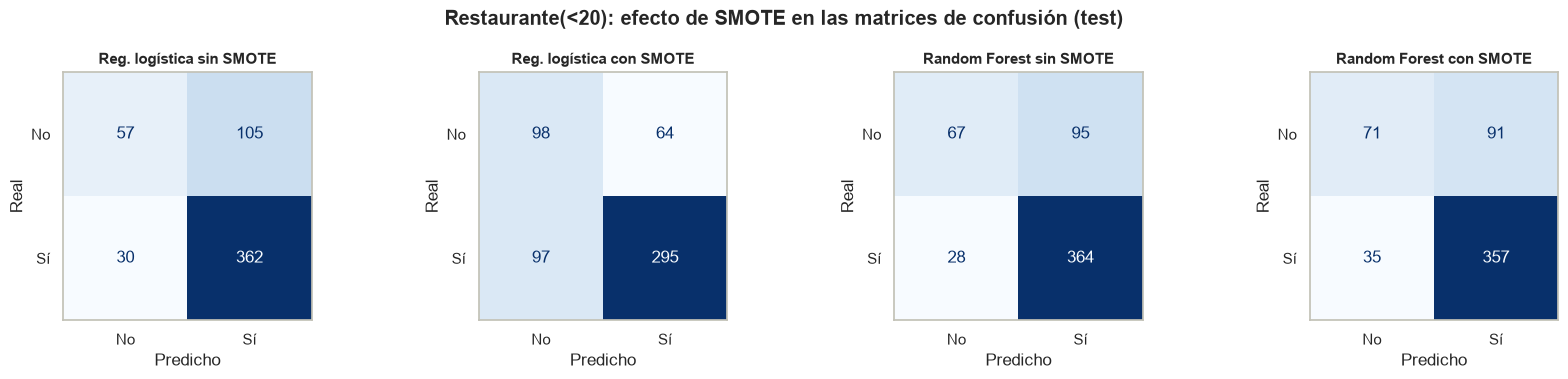

In [29]:
matrices_confusion({
    "Reg. logística sin SMOTE": gs_lr_rest.best_estimator_,
    "Reg. logística con SMOTE": busquedas_smote["Regresión logística"].best_estimator_,
    "Random Forest sin SMOTE": gs_rf_rest.best_estimator_,
    "Random Forest con SMOTE": busquedas_smote["Random Forest"].best_estimator_,
}, X_test_rest, y_test_rest, "Restaurante(<20): efecto de SMOTE en las matrices de confusión (test)")

Las salidas cuentan la historia completa:

1. **SMOTE solo tocó el entrenamiento.** El train pasó de 1567 "Sí" y 648 "No" a 1567 y 1567, mientras que el test se quedó con su distribución original (392 y 162).
2. **En la regresión logística SMOTE cambia mucho el comportamiento.** El recall de "No" sube de 0.352 a 0.605 (pasa de reconocer 57 a 98 rechazos), pero lo paga caro: el recall de "Sí" cae de 0.923 a 0.753 (las aceptaciones perdidas pasan de 30 a 97), la precisión de "No" baja de 0.655 a 0.503 y el F1 de la clase positiva baja de 0.843 a 0.786. El F1 macro mejora un poco (de 0.650 a 0.667).
3. **En los modelos de árboles el efecto es pequeño.** En el árbol de decisión el recall de "No" sube de 0.383 a 0.414 y el F1 baja de 0.840 a 0.829. En Random Forest el recall de "No" pasa de 0.414 a 0.438 (4 rechazos más bien identificados, de 162), el F1 baja de 0.855 a 0.850 y el F1 macro queda prácticamente igual (0.688 frente a 0.690).

En otras palabras, SMOTE no hace al modelo "mejor": lo mueve a otro punto del trade-off entre precisión y recall, a favor de la clase "No". En la regresión logística ese movimiento es grande; en Random Forest casi no se nota. Nuestra explicación es que el bosque, con árboles profundos y hojas de una muestra, ya separa bastante bien las regiones donde están los "No", y los puntos sintéticos caen justo en esas mismas regiones, así que no le enseñan nada nuevo.

Si lo que se quiere es mover ese trade-off, hay una forma más directa que no necesita datos sintéticos: cambiar el umbral de decisión del Random Forest. Abajo lo probamos con probabilidades de validación cruzada sobre el entrenamiento, sin tocar el test.

In [30]:
# Probabilidades fuera de fold sobre el train (no se usa el test para esto)
proba_oof = cross_val_predict(clone(gs_rf_rest.best_estimator_), X_train_rest, y_train_rest,
                              cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
filas = []
for umbral in [0.50, 0.55, 0.60, 0.65, 0.70]:
    pred = (proba_oof >= umbral).astype(int)
    filas.append({
        "Umbral": umbral,
        "Precision": precision_score(y_train_rest, pred),
        "Recall": recall_score(y_train_rest, pred),
        "F1": f1_score(y_train_rest, pred),
        "Precision clase No": precision_score(y_train_rest, pred, pos_label=0),
        "Recall clase No": recall_score(y_train_rest, pred, pos_label=0),
        "F1 macro": f1_score(y_train_rest, pred, average="macro"),
    })
pd.DataFrame(filas).set_index("Umbral").round(3)

,Precision,Recall,F1,Precision clase No,Recall clase No,F1 macro
Umbral,,,,,,
0.50,0.801,0.920,0.856,0.696,0.446,0.700
0.55,0.809,0.881,0.843,0.633,0.495,0.700
0.60,0.823,0.846,0.834,0.600,0.560,0.707
0.65,0.835,0.807,0.821,0.568,0.614,0.705
0.70,0.844,0.742,0.790,0.517,0.668,0.686


Con el umbral se consigue el mismo tipo de efecto que con SMOTE, pero de forma controlada. Subiendo el umbral de 0.50 a 0.55 el recall de "No" pasa de 0.446 a 0.495, una ganancia algo mayor que la que dio SMOTE en este mismo modelo, y si se quiere priorizar todavía más la clase "No" se llega a 0.560 con un umbral de 0.60 o a 0.614 con 0.65, a cambio de bajar el F1 de "Sí" a 0.834 y 0.821. SMOTE en el Random Forest no permite llegar ahí. Además, el umbral no requiere reentrenar ni inventar datos: basta con escogerlo según cuánto le cueste a Ruta Alpes cada tipo de error.

**Recomendación.** Para Restaurante(&lt;20) **no recomendamos aplicar SMOTE** en el modelo final:

- En el mejor modelo (Random Forest) la mejora en el recall de la clase minoritaria es marginal (de 0.414 a 0.438), mientras que el F1 general baja un poco (de 0.855 a 0.850) y la precisión de "No" también (de 0.705 a 0.670).
- Donde SMOTE sí tiene un efecto grande (regresión logística), el modelo sigue siendo peor que el Random Forest sin balancear, y la ganancia en recall de "No" se paga con 67 aceptaciones perdidas adicionales en el test.
- Agrega datos sintéticos que, con variables categóricas, no corresponden a conductores reales.

Eso no quiere decir que el desbalance no importe. La decisión de fondo es de negocio: un falso positivo (mandar un cupón que se rechaza) es una notificación molesta, y un falso negativo (no mandar un cupón que se habría aceptado) es una venta perdida. Si Ruta Alpes considera que molestar al conductor le sale más caro que perder una venta, lo que recomendamos es subir el umbral de decisión del Random Forest, escogiéndolo con validación cruzada como en la tabla, en vez de balancear con SMOTE. Para la entrega, que se evalúa con F1, dejamos el Random Forest sin SMOTE y con el umbral estándar de 0.5.

## 9. Actividad 7: Tabla comparativa

Todas las métricas son sobre el conjunto de **test** (el 20% que no se usó ni para entrenar ni para escoger hiperparámetros), tomando "Sí" como clase positiva. Agregamos el recall de la clase "No", el F1 macro y el F1 de validación cruzada como referencia.

Precision  Recall     F1  Recall clase No  F1 macro  F1 CV                                    Hiperparámetros
Cupón            Modelo                                                                                                                            
Cafetería        Regresión logística      0.688   0.705  0.697            0.682     0.693  0.707                       C=1, penalty=l1, solver=saga
                 Árbol de decisión        0.678   0.695  0.687            0.672     0.683  0.711  criterion=entropy, max_depth=5, min_samples_le...
                 Random Forest            0.777   0.773  0.775            0.779     0.776  0.760  max_depth=None, max_features=0.3, min_samples_...
Restaurante(<20) Regresión logística      0.775   0.923  0.843            0.352     0.650  0.848                C=0.1, penalty=l2, solver=liblinear
                 Árbol de decisión        0.781   0.908  0.840            0.383     0.658  0.843   criterion=gini, max_depth=3, min_samples_leaf=10
                 Random Forest            0.793   0.929  0.855            0.414     0.688  0.855  max_depth=None, max_features=sqrt, min_samples...

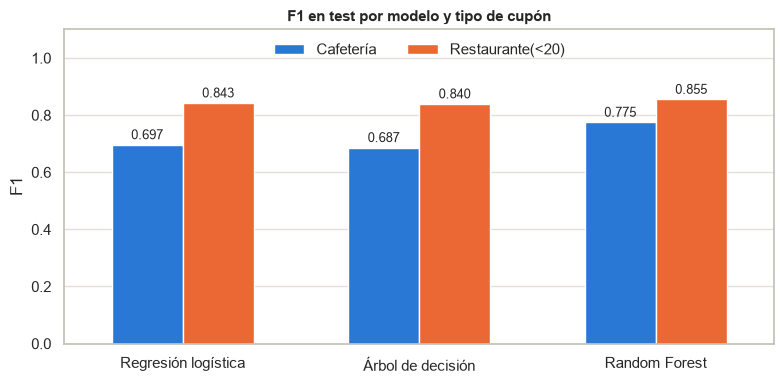

Mejor modelo para Cafetería: Random Forest
Mejor modelo para Restaurante(<20): Random Forest


In [31]:
tabla_comparativa = pd.concat([
    df_resultados_cafe.assign(Cupón="Cafetería"),
    df_resultados_rest.assign(Cupón="Restaurante(<20)"),
]).reset_index().set_index(["Cupón", "Modelo"])
tabla_comparativa = tabla_comparativa[["Precision", "Recall", "F1", "Recall clase No", "F1 macro", "F1 CV",
                                       "Hiperparámetros"]]
display(tabla_comparativa.round(3))

datos_f1 = tabla_comparativa["F1"].reset_index()
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=datos_f1, x="Modelo", y="F1", hue="Cupón", palette=COLORES, width=0.6, saturation=1)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", padding=2, fontsize=9)
plt.ylim(0, 1.1)
plt.title("F1 en test por modelo y tipo de cupón")
plt.xlabel("")
plt.legend(title=None, loc="upper center", ncol=2, frameon=False)
plt.tight_layout()
plt.show()

mejor_nombre_cafe = df_resultados_cafe["F1"].idxmax()
mejor_nombre_rest = df_resultados_rest["F1"].idxmax()
mejor_busqueda = {"Cafetería": busquedas_cafe[mejor_nombre_cafe], "Restaurante(<20)": busquedas_rest[mejor_nombre_rest]}
print(f"Mejor modelo para Cafetería: {mejor_nombre_cafe}")
print(f"Mejor modelo para Restaurante(<20): {mejor_nombre_rest}")

**Selección del mejor modelo por cupón:**

- **Cafetería: Random Forest.** Gana en todas las métricas y con margen: F1 de 0.775 frente a 0.697 de la regresión logística y 0.687 del árbol. Además es igual de bueno identificando a los que aceptan (recall de 0.773) que a los que no (0.779), que es lo que uno quiere en un problema balanceado. La diferencia también se ve en validación cruzada (0.760 frente a 0.707 y 0.711), así que no es suerte del test.
- **Restaurante(&lt;20): Random Forest.** Tiene el mejor F1 (0.855), la mejor precisión (0.793) y el mejor recall de "No" (0.414) de los tres. Aquí la ventaja es menor (1.2 puntos de F1 sobre la regresión logística), pero como también es el que mejor maneja la clase minoritaria (F1 macro de 0.688 frente a 0.650 y 0.658), no hay un trade-off que nos haga dudar.

¿Por qué gana Random Forest? Porque en estos datos los efectos no son aditivos ni lineales. La hora tiene picos (10 a.m. para el café; almuerzo y comida para el restaurante) y hay interacciones claras: la distancia pesa cuando el clima es malo pero casi nada con sol, un cupón de 2 horas se acepta mucho menos a las 10 p.m. que en el resto del día, y entre quienes sí van a cafeterías el destino y la dirección cambian bastante la probabilidad. La regresión logística no puede representar eso sin que uno construya las interacciones a mano, y un árbol solo lo captura, pero es inestable y se sobreajusta rápido. El bosque promedia muchos árboles distintos y logra capturar esas interacciones sin depender de uno solo.

Desde el punto de vista del negocio también es una buena elección: predecir con un Random Forest toma milisegundos y entrega una probabilidad, que es justo lo que se necesita para decidir en tiempo real si vale la pena mostrar un cupón. Lo que se pierde es interpretabilidad directa, y para eso usamos el árbol y la regresión logística como apoyo en la siguiente sección.

## 10. Actividad 8: Variables más relevantes

Para no quedarnos con una sola mirada, revisamos la importancia de las variables de tres formas, porque cada una responde una pregunta distinta:

1. **Importancia por impureza (MDI) del Random Forest:** cuánto ayuda cada variable a "limpiar" los nodos de los árboles. Es la que trae scikit-learn por defecto, pero tiene un sesgo conocido a favor de las variables con muchos valores posibles. Para que sea comparable, sumamos la importancia de todas las dummies de una misma variable.
2. **Importancia por permutación en test:** cuánto empeora el modelo cuando se desordena una variable en el test. Usamos la caída del AUC y no la del F1, porque en Restaurante(&lt;20) el modelo predice "Sí" para casi todos y desordenar una variable rara vez cambia esa predicción; el F1 casi no se mueve y no deja distinguir nada. El AUC, en cambio, mide qué tan bien ordena el modelo a los que aceptan por encima de los que no, sin depender del umbral.
3. **Coeficientes de la regresión logística:** son los únicos que dicen la **dirección** del efecto (si sube o baja la probabilidad de aceptar). Como todas las variables están en [0, 1], cada coeficiente es el cambio en log-odds al pasar del valor más bajo al más alto de esa variable.

Ninguna de las dos importancias del bosque dice si una variable sube o baja la aceptación; para eso están los coeficientes y las gráficas de la exploración.

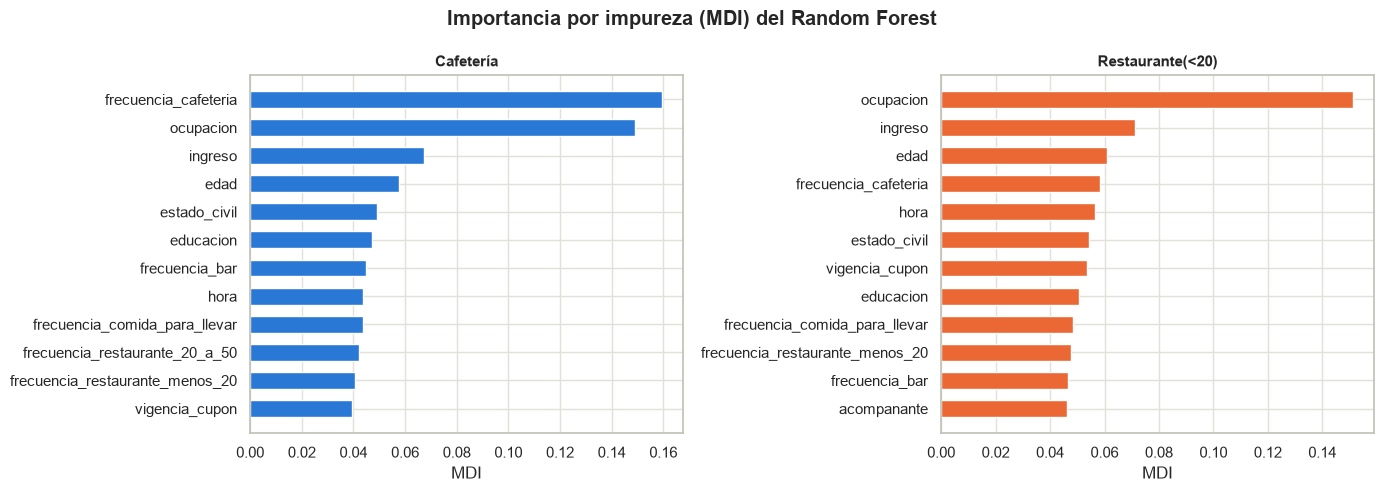

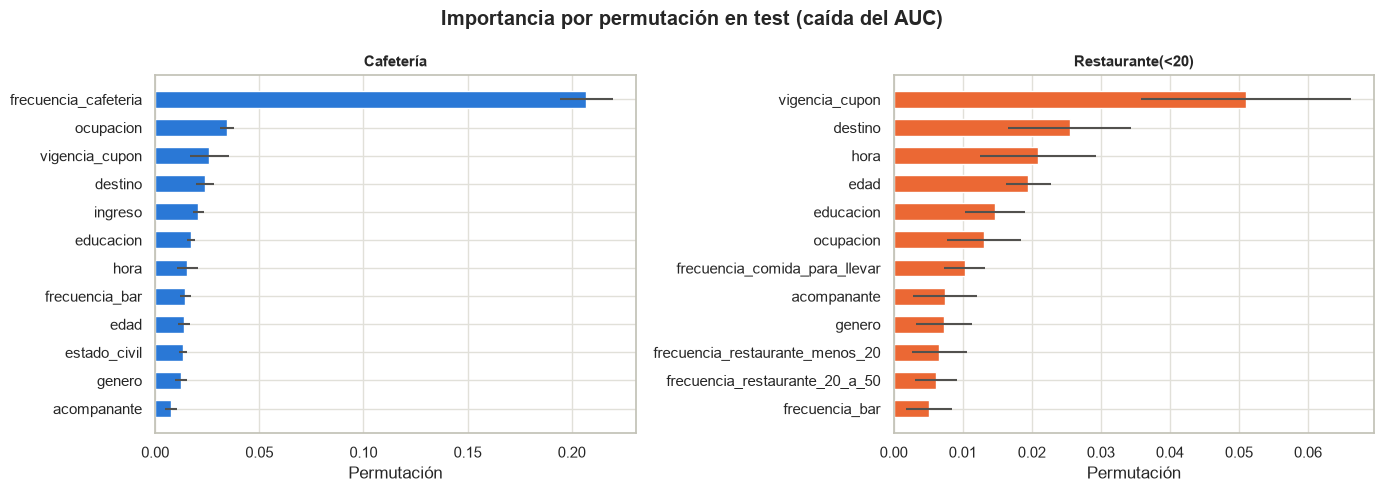

In [32]:
def importancias_rf(busqueda, X_test, y_test):
    modelo = busqueda.best_estimator_
    nombres = modelo.named_steps["preprocessor"].get_feature_names_out()
    # MDI agrupada por variable original (se suman las dummies del one-hot)
    origen = [n if n in X_test.columns else next(c for c in NOMINAL_COLS if n.startswith(c + "_")) for n in nombres]
    mdi = pd.Series(modelo.named_steps["model"].feature_importances_, index=nombres).groupby(origen).sum()
    perm = permutation_importance(modelo, X_test, y_test, scoring="roc_auc", n_repeats=10,
                                  random_state=RANDOM_STATE, n_jobs=-1)
    return pd.DataFrame({
        "MDI": mdi.reindex(X_test.columns),
        "Permutación": perm.importances_mean,
        "Permutación std": perm.importances_std,
    }, index=X_test.columns)


importancias = {
    "Cafetería": importancias_rf(gs_rf_cafe, X_test_cafe, y_test_cafe),
    "Restaurante(<20)": importancias_rf(gs_rf_rest, X_test_rest, y_test_rest),
}

for medida, titulo in [("MDI", "Importancia por impureza (MDI) del Random Forest"),
                       ("Permutación", "Importancia por permutación en test (caída del AUC)")]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, cupon in zip(axes, CUPONES):
        top = importancias[cupon].sort_values(medida, ascending=False).head(12)
        error = top["Permutación std"] if medida == "Permutación" else None
        ax.barh(top.index[::-1], top[medida][::-1], color=COLORES[cupon], height=0.6,
                xerr=None if error is None else error[::-1], ecolor="#52514e")
        ax.set_title(cupon)
        ax.set_xlabel(medida)
    fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [33]:
ranking = pd.concat({
    cupon: importancias[cupon].sort_values("Permutación", ascending=False)
           .assign(Puesto=lambda d: range(1, len(d) + 1))[["Puesto", "Permutación", "MDI"]]
    for cupon in CUPONES
}, axis=1)
ranking.sort_values(("Cafetería", "Puesto")).round(4)

Cafetería                     Restaurante(<20)                    
                                   Puesto Permutación     MDI           Puesto Permutación     MDI
frecuencia_cafeteria                    1      0.2069  0.1596               20     -0.0001  0.0582
ocupacion                               2      0.0346  0.1490                6      0.0131  0.1514
vigencia_cupon                          3      0.0260  0.0395                1      0.0510  0.0537
destino                                 4      0.0238  0.0383                2      0.0255  0.0436
ingreso                                 5      0.0207  0.0671               13      0.0051  0.0712
educacion                               6      0.0172  0.0470                5      0.0147  0.0505
hora                                    7      0.0154  0.0437                3      0.0209  0.0566
frecuencia_bar                          8      0.0143  0.0450               12      0.0051  0.0465
edad                                    9      0.0137  0.0575                4      0.0195  0.0610
estado_civil                           10      0.0135  0.0492               15      0.0019  0.0543
genero                                 11      0.0122  0.0293                9      0.0073  0.0346
acompanante                            12      0.0076  0.0386                8      0.0075  0.0464
frecuencia_comida_para_llevar          13      0.0069  0.0436                7      0.0103  0.0485
frecuencia_restaurante_20_a_50         14      0.0069  0.0421               11      0.0061  0.0438
frecuencia_restaurante_menos_20        15      0.0064  0.0404               10      0.0066  0.0477
misma_direccion                        16      0.0057  0.0159               16      0.0017  0.0083
temperatura                            17      0.0049  0.0224               18      0.0008  0.0230
tiene_hijos                            18      0.0028  0.0154               17      0.0015  0.0170
tiempo_cupon_mayor_25min               19      0.0021  0.0113               14      0.0033  0.0231
clima                                  20     -0.0003  0.0155               21     -0.0007  0.0421
tiempo_cupon_mayor_15min               21     -0.0004  0.0294               19      0.0006  0.0184

**Lo que dicen las importancias del Random Forest:**

- En **Cafetería** no hay discusión: `frecuencia_cafeteria` es la variable más importante con las dos medidas, y por mucho. Al desordenarla el AUC cae 0.21, unas seis veces más que con la segunda. Después vienen `ocupacion`, `vigencia_cupon`, `destino`, `ingreso` y `educacion`.
- En **Restaurante(&lt;20)** las dos medidas no coinciden. Por impureza las primeras son `ocupacion`, `ingreso` y `edad`; por permutación, `vigencia_cupon`, `destino` y `hora`, y ninguna domina como lo hace el hábito en Cafetería.

¿Por qué no coinciden? Por dos razones. La primera es el sesgo de la MDI: `ocupacion` (25 categorías) e `ingreso` (9 niveles) ofrecen muchísimos puntos de corte, así que los árboles las usan mucho aunque cada corte aporte poco. La segunda es más interesante: el bosque usa las variables de perfil para reconocer a cada conductor. Como cada persona aparece en varios escenarios, la combinación de ocupación, ingreso, edad y estado civil funciona casi como una cédula, y el modelo aprende cosas como "esta persona suele aceptar". Lo comprobamos en la sección 11.

También hay que leer con cuidado los ceros. `clima`, `temperatura` y `tiempo_cupon_mayor_25min` salen con importancia por permutación muy baja en Restaurante(&lt;20), aunque en la exploración estaban entre las más relacionadas con la aceptación. No es que no importen: como vienen "en paquete" (mal clima, distancia, madrugada o noche y vigencia corta suelen ir juntos), cuando se desordena una el bosque compensa con las otras. La permutación subestima las variables que comparten información.

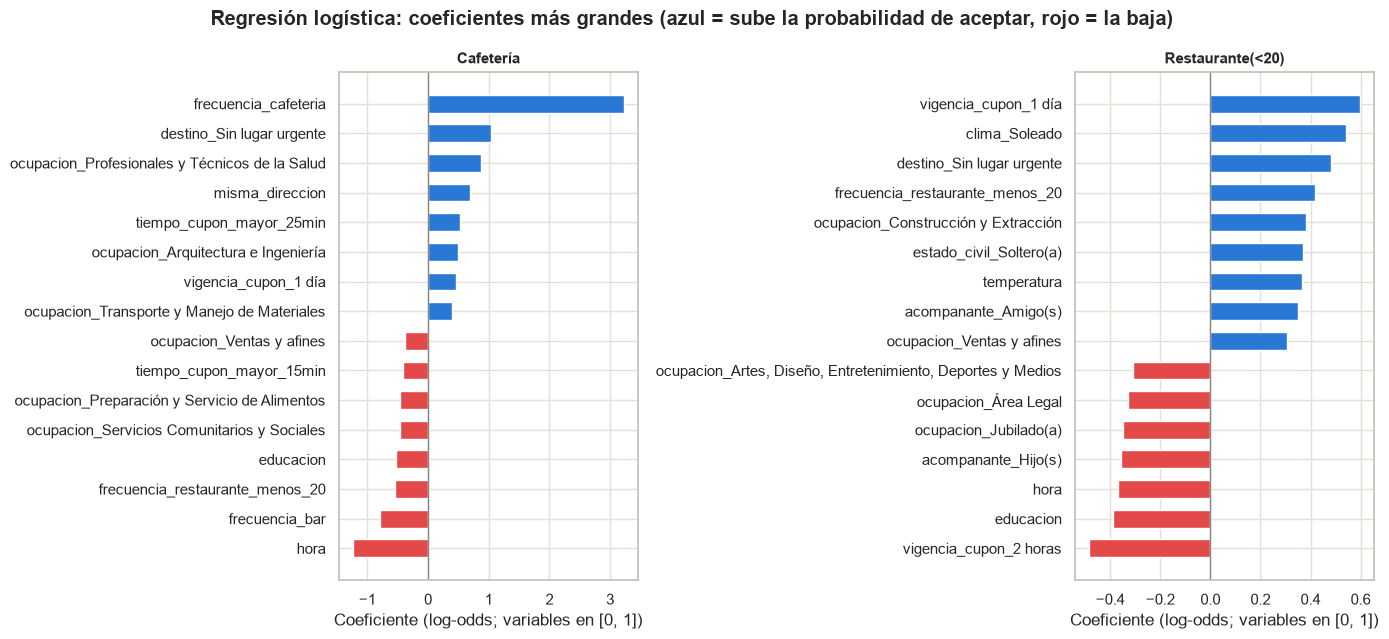

Cafetería: 8 coeficientes en cero -> ['destino_Casa', 'clima_Lluvioso', 'estado_civil_Soltero(a)', 'estado_civil_Viudo(a)', 'ocupacion_Artes, Diseño, Entretenimiento, Deportes y Medios', 'ocupacion_Ciencias Naturales y Sociales', 'ocupacion_Estudiante', 'ocupacion_Producción']
Restaurante(<20): 0 coeficientes en cero -> []


In [34]:
def coeficientes_lr(busqueda):
    modelo = busqueda.best_estimator_
    nombres = modelo.named_steps["preprocessor"].get_feature_names_out()
    return pd.Series(modelo.named_steps["model"].coef_[0], index=nombres)


coeficientes = {"Cafetería": coeficientes_lr(gs_lr_cafe), "Restaurante(<20)": coeficientes_lr(gs_lr_rest)}

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, cupon in zip(axes, CUPONES):
    coef = coeficientes[cupon]
    top = coef.loc[coef.abs().sort_values(ascending=False).head(16).index].sort_values()
    ax.barh(top.index, top.values, color=np.where(top.values > 0, "#2a78d6", "#e34948"), height=0.6)
    ax.axvline(0, color="#898781", linewidth=1)
    ax.set_title(cupon)
    ax.set_xlabel("Coeficiente (log-odds; variables en [0, 1])")
fig.suptitle("Regresión logística: coeficientes más grandes (azul = sube la probabilidad de aceptar, rojo = la baja)",
             fontweight="bold")
plt.tight_layout()
plt.show()

for cupon in CUPONES:
    nulos = coeficientes[cupon][coeficientes[cupon].abs() < 1e-6]
    print(f"{cupon}: {len(nulos)} coeficientes en cero -> {list(nulos.index)}")

**Lo que dicen los coeficientes de la regresión logística (dirección del efecto):**

*Cafetería* (L1, `C = 1`):
- `frecuencia_cafeteria` tiene de lejos el coeficiente más grande (+3.23): pasar de "nunca" a "más de 8 veces al mes" multiplica los odds de aceptar por unas 25 veces.
- Suben la probabilidad: ir "Sin lugar urgente" (+1.04), que el lugar quede en la misma dirección (+0.70) y la vigencia de 1 día (+0.46, frente a -0.33 de la de 2 horas).
- La bajan: la hora (-1.25; la tendencia es a aceptar menos a medida que avanza el día), ir con frecuencia a bares (-0.80) y a restaurantes baratos (-0.55), y un mayor nivel educativo (-0.53).
- L1 dejó 8 coeficientes en cero, todos de categorías sueltas (por ejemplo `destino_Casa` o algunas ocupaciones). Eso quiere decir que esas categorías quedaron iguales a la referencia, no que la variable completa sobre.

*Restaurante(&lt;20)* (L2, `C = 0.1`):
- Los coeficientes son más pequeños y parejos, sin una variable que domine. Suben la probabilidad la vigencia de 1 día (+0.60), el clima soleado (+0.54), ir "Sin lugar urgente" (+0.48), ir seguido a restaurantes baratos (+0.42), una mayor temperatura (+0.37) e ir con amigos (+0.35).
- La bajan la vigencia de 2 horas (-0.49), un mayor nivel educativo (-0.39), la hora (-0.37), ir con los hijos (-0.36) y algunas ocupaciones, como jubilado(a) (-0.35).

Un par de signos son contraintuitivos y vale la pena advertirlo. En Cafetería `tiempo_cupon_mayor_25min` sale positivo (+0.53) y en Restaurante(&lt;20) casi en cero (-0.07), cuando en la exploración la distancia larga bajaba mucho la aceptación. No es que la distancia ayude: como los cupones lejanos casi siempre coinciden con madrugada o noche, trabajo, ir solo y vigencia de 2 horas, el modelo ya "cobra" ese efecto en esas otras variables. Los coeficientes se interpretan dejando todo lo demás fijo, y con variables tan amarradas eso no siempre tiene sentido en la práctica.

In [35]:
def describir_condicion(variable, umbral, izquierda):
    # Traduce los umbrales codificados del árbol a las categorías originales
    if variable in ORDINAL_CATEGORIES:
        categorias, k = ORDINAL_CATEGORIES[variable], int(np.floor(umbral))
        return f"{variable} hasta '{categorias[k]}'" if izquierda else f"{variable} desde '{categorias[k + 1]}'"
    if variable in BINARY_COLS:
        return f"{variable} = {'No' if izquierda else 'Sí'}"
    nominal = next((c for c in NOMINAL_COLS if variable.startswith(c + "_")), None)
    if nominal:
        return f"{nominal} {'distinto de' if izquierda else '='} '{variable[len(nominal) + 1:]}'"
    return f"{variable} {'<=' if izquierda else '>'} {umbral:.1f}"


def reglas_arbol(busqueda, profundidad=3):
    arbol = busqueda.best_estimator_
    tree = arbol.named_steps["model"].tree_
    nombres = arbol.named_steps["preprocessor"].get_feature_names_out()

    def recorrer(nodo, nivel, condicion):
        valores = tree.value[nodo][0]
        print(f"{'    ' * nivel}{condicion}  ->  n = {tree.n_node_samples[nodo]}, acepta el {valores[1] / valores.sum():.0%}")
        if tree.children_left[nodo] != -1 and nivel < profundidad:
            variable, umbral = nombres[tree.feature[nodo]], tree.threshold[nodo]
            recorrer(tree.children_left[nodo], nivel + 1, describir_condicion(variable, umbral, True))
            recorrer(tree.children_right[nodo], nivel + 1, describir_condicion(variable, umbral, False))

    recorrer(0, 0, "Todos los escenarios de entrenamiento")


for cupon, busqueda in [("Cafetería", gs_dt_cafe), ("Restaurante(<20)", gs_dt_rest)]:
    print(f"=============== {cupon}: primeros 3 niveles del mejor árbol ===============")
    reglas_arbol(busqueda)
    print()

=============== Cafetería: primeros 3 niveles del mejor árbol ===============
Todos los escenarios de entrenamiento  ->  n = 3183, acepta el 50%
    frecuencia_cafeteria hasta 'nunca'  ->  n = 736, acepta el 19%
        ingreso hasta '$62.500 - $74.999'  ->  n = 534, acepta el 24%
            frecuencia_restaurante_20_a_50 hasta 'menos de 1'  ->  n = 435, acepta el 20%
            frecuencia_restaurante_20_a_50 desde '1 a 3'  ->  n = 99, acepta el 40%
        ingreso desde '$75.000 - $87.499'  ->  n = 202, acepta el 8%
            frecuencia_comida_para_llevar hasta 'menos de 1'  ->  n = 28, acepta el 29%
            frecuencia_comida_para_llevar desde '1 a 3'  ->  n = 174, acepta el 5%
    frecuencia_cafeteria desde 'menos de 1'  ->  n = 2447, acepta el 59%
        destino distinto de 'Sin lugar urgente'  ->  n = 1121, acepta el 48%
            misma_direccion = No  ->  n = 678, acepta el 38%
            misma_direccion = Sí  ->  n = 443, acepta el 63%
        destino = 'Sin lugar urg

**Reglas de los árboles de decisión.** La función traduce los umbrales de las variables codificadas a sus categorías originales; "acepta el X%" es el porcentaje de "Sí" entre los escenarios de entrenamiento que caen en ese nodo.

- **Cafetería.** La primera pregunta del árbol es si el conductor va a cafeterías. Si nunca va (736 escenarios), solo acepta el 19%, y si además el ingreso de su hogar es de 75.000 dólares o más, la aceptación cae al 8%. Si sí va, la aceptación sube a 59% y lo siguiente que importa es el destino: sin lugar urgente llega a 68% (74% si va de 1 a 3 veces al mes o más), mientras que yendo a casa o al trabajo depende de si el café queda en la misma dirección (63% si sí, 38% si no).
- **Restaurante(&lt;20).** La primera pregunta es la distancia. Si el restaurante queda a más de 25 minutos solo acepta el 33%, salvo cuando va con la pareja (83%, aunque son apenas 23 escenarios). Si queda más cerca (76%), importa la vigencia: con cupón de 1 día y temperatura de 55 °F o más se llega al 86%; con cupón de 2 horas la aceptación es de 71% hasta las 6 p.m., pero a las 10 p.m. baja a 49%, la única hoja de ese lado del árbol donde predice "No".

### 10.1 Comparación entre los dos cupones

Juntando las tres miradas queda una idea bastante clara: **el cupón de Cafetería depende de quién es el conductor y el de Restaurante(&lt;20) depende de en qué situación está.**

| | Cafetería | Restaurante(&lt;20) |
|---|---|---|
| Variable que domina | `frecuencia_cafeteria` (el hábito), muy por encima del resto | Ninguna; varias de contexto con peso parecido |
| Contexto del viaje | Destino, vigencia, hora y dirección importan, pero en segundo plano | Es lo principal: vigencia, destino, hora, distancia y clima |
| Hábito del mismo tipo de establecimiento | Decisivo (de 19% a 65-69% de aceptación) | Ayuda, pero poco (de 56% a 76%) |
| Clima | Casi no influye | Influye bastante (39-49% con lluvia o nieve frente a 77% con sol) |
| Variables demográficas | Las usa el bosque, en buena parte para reconocer conductores | Altas en MDI; en permutación solo destacan edad y educación, con un aporte real pero pequeño |

En lo que sí coinciden: la vigencia del cupón y el destino están entre las variables más importantes de los dos, ir solo baja la aceptación en ambos casos, y `genero` y `tiene_hijos` casi no tienen relación directa con aceptar (V de Cramér por debajo de 0.03).

Para Ruta Alpes esto tiene una consecuencia práctica. En Cafetería conviene segmentar por hábito y no insistir con quien nunca va a cafeterías. En Restaurante(&lt;20) conviene escoger bien el momento: cupones de 1 día, cerca de la hora de almuerzo o de comida, con buen clima y cerca de la ruta.

## 11. Análisis de resultados

Antes de responder las preguntas hicimos tres experimentos cortos que nos sirven como evidencia para varias de las respuestas.

### 11.1 ¿Qué tan bien funcionan los modelos con conductores que nunca han visto?

En la exploración vimos que cada conductor aparece en varios escenarios. Con la partición aleatoria el mismo conductor puede quedar en train y en test, así que las métricas que reportamos miden qué tan bien predice el modelo **situaciones nuevas de conductores que ya conoce**. Para ver qué pasa con conductores nuevos comparamos la validación cruzada normal con una validación cruzada agrupada por conductor (`StratifiedGroupKFold`), en la que todas las filas de una misma persona quedan en el mismo fold. Como no hay un identificador de persona, usamos el perfil completo (demografía y hábitos) como aproximación.

In [36]:
def grupos_conductor(X):
    # Usamos el perfil (demografía + hábitos) como aproximación a la identidad del conductor
    return X[PERFIL].fillna("sin dato").astype(str).agg("|".join, axis=1)


conocidos = df_test_full[PERFIL].merge(df[PERFIL].drop_duplicates(), how="inner")
print(f"Perfiles del archivo de prueba que ya aparecen en los datos etiquetados: {len(conocidos)} de {len(df_test_full)}")

cv_por_conductor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
filas = []
for cupon, X, y, busquedas in [("Cafetería", X_cafe, y_cafe, busquedas_cafe),
                               ("Restaurante(<20)", X_rest, y_rest, busquedas_rest)]:
    grupos = grupos_conductor(X)
    for nombre in ["Regresión logística", "Random Forest"]:
        modelo = busquedas[nombre].best_estimator_
        f1_conocidos = cross_val_score(clone(modelo), X, y, cv=cv, scoring="f1", n_jobs=-1)
        f1_nuevos = cross_val_score(clone(modelo), X, y, groups=grupos, cv=cv_por_conductor, scoring="f1", n_jobs=-1)
        filas.append({"Cupón": cupon, "Modelo": nombre,
                      "F1 conductores ya vistos": f1_conocidos.mean(),
                      "F1 conductores nuevos": f1_nuevos.mean(),
                      "Diferencia": f1_nuevos.mean() - f1_conocidos.mean()})
pd.DataFrame(filas).set_index(["Cupón", "Modelo"]).round(3)

Perfiles del archivo de prueba que ya aparecen en los datos etiquetados: 20 de 20


F1 conductores ya vistos  F1 conductores nuevos  Diferencia
Cupón            Modelo                                                                          
Cafetería        Regresión logística                     0.698                  0.682      -0.017
                 Random Forest                           0.771                  0.707      -0.064
Restaurante(<20) Regresión logística                     0.846                  0.842      -0.004
                 Random Forest                           0.851                  0.843      -0.008

Con conductores nuevos el Random Forest de Cafetería pierde 6.4 puntos de F1 (de 0.771 a 0.707), mientras que la regresión logística solo pierde 1.7 (de 0.698 a 0.682). Es decir, buena parte de la ventaja del bosque en Cafetería viene de reconocer a personas que ya vio, no solo de entender el contexto. En Restaurante(&lt;20) la caída es de menos de 1 punto para los dos modelos, lo que cuadra con que ahí la decisión depende más de la situación que de la persona.

Para el archivo de prueba que se entrega esto no es un problema, porque sus 20 perfiles ya aparecen en los datos etiquetados (primera línea de la salida). Pero sí lo es para los usuarios nuevos de una app real.

### 11.2 ¿Qué tanto aportan las variables demográficas?

Repetimos las dos validaciones con el mismo Random Forest ganador de cada cupón, pero quitando las siete variables demográficas (género, edad, estado civil, hijos, educación, ocupación e ingreso). Solo quedan el contexto del viaje y los hábitos de consumo.

In [37]:
DEMOGRAFICAS = ["genero", "edad", "estado_civil", "tiene_hijos", "educacion", "ocupacion", "ingreso"]

filas = []
for cupon, X, y in [("Cafetería", X_cafe, y_cafe), ("Restaurante(<20)", X_rest, y_rest)]:
    grupos = grupos_conductor(X)
    for variables, excluir in [("Todas", ()), ("Sin demográficas", DEMOGRAFICAS)]:
        # Mismo Random Forest ganador; solo cambia qué columnas entran al preprocesador
        modelo = clone(mejor_busqueda[cupon].best_estimator_).set_params(
            preprocessor=build_preprocessor(excluir=excluir))
        vistos = cross_validate(modelo, X, y, cv=cv, scoring=["f1", "f1_macro"], n_jobs=-1)
        nuevos = cross_validate(modelo, X, y, groups=grupos, cv=cv_por_conductor, scoring=["f1", "f1_macro"], n_jobs=-1)
        filas.append({"Cupón": cupon, "Variables": variables,
                      "F1 ya vistos": vistos["test_f1"].mean(), "F1 nuevos": nuevos["test_f1"].mean(),
                      "F1 macro ya vistos": vistos["test_f1_macro"].mean(),
                      "F1 macro nuevos": nuevos["test_f1_macro"].mean()})
pd.DataFrame(filas).set_index(["Cupón", "Variables"]).round(3)

F1 ya vistos  F1 nuevos  F1 macro ya vistos  F1 macro nuevos
Cupón            Variables                                                                     
Cafetería        Todas                    0.771      0.707               0.768            0.700
                 Sin demográficas         0.700      0.673               0.695            0.671
Restaurante(<20) Todas                    0.851      0.843               0.689            0.664
                 Sin demográficas         0.820      0.818               0.649            0.645

Quitar las variables demográficas sí cuesta: con conductores ya vistos el F1 baja de 0.771 a 0.700 en Cafetería y de 0.851 a 0.820 en Restaurante(&lt;20). Pero lo interesante es comparar las columnas. En Cafetería la demografía aporta 7.1 puntos con conductores ya vistos, y solo 3.4 con conductores nuevos (0.707 frente a 0.673). O sea, más o menos la mitad de lo que aporta la demografía en Cafetería es reconocer a personas que el modelo ya vio, y eso no se puede generalizar a un usuario nuevo. En Restaurante(&lt;20) el aporte es parecido en los dos casos (3.1 y 2.5 puntos), lo que sugiere que ahí sí hay algo de señal real en variables como la edad o la educación, aunque pequeña.

Esto pesa en la discusión ética: usar datos demográficos sí mejora las métricas, pero menos de lo que hace pensar la importancia de variables, y una parte de esa mejora es memorizar personas.

### 11.3 ¿El modelo se equivoca igual con todos los grupos?

Con el modelo final de cada cupón comparamos, en el test, la tasa real de aceptación, la tasa que predice el modelo y el recall de cada clase por género y por grupo de edad.

In [38]:
GRUPOS_EDAD = {"menor de 21": "Menos de 26", "21": "Menos de 26", "26": "26 a 40", "31": "26 a 40",
               "36": "26 a 40", "41": "41 a 49", "46": "41 a 49", "50 o más": "50 o más"}

filas = []
for cupon, X_te, y_te in [("Cafetería", X_test_cafe, y_test_cafe), ("Restaurante(<20)", X_test_rest, y_test_rest)]:
    pred = pd.Series(mejor_busqueda[cupon].best_estimator_.predict(X_te), index=y_te.index)
    for variable, grupos, orden in [
        ("genero", X_te["genero"], ["Femenino", "Masculino"]),
        ("edad", X_te["edad"].map(GRUPOS_EDAD), ["Menos de 26", "26 a 40", "41 a 49", "50 o más"]),
    ]:
        for grupo in orden:
            mascara = grupos == grupo
            yt, yp = y_te[mascara], pred[mascara]
            filas.append({"Cupón": cupon, "Variable": variable, "Grupo": grupo, "n": int(mascara.sum()),
                          "% acepta real": yt.mean(), "% acepta predicho": yp.mean(),
                          "Recall": recall_score(yt, yp), "Recall clase No": recall_score(yt, yp, pos_label=0),
                          "F1": f1_score(yt, yp)})
pd.DataFrame(filas).set_index(["Cupón", "Variable", "Grupo"]).round(3)

n  % acepta real  % acepta predicho  Recall  Recall clase No     F1
Cupón            Variable Grupo                                                                             
Cafetería        genero   Femenino     401          0.504              0.501   0.777            0.779  0.779
                          Masculino    395          0.494              0.491   0.769            0.780  0.771
                 edad     Menos de 26  199          0.558              0.553   0.820            0.784  0.824
                          26 a 40      377          0.509              0.493   0.760            0.784  0.772
                          41 a 49      119          0.479              0.521   0.754            0.694  0.723
                          50 o más     101          0.366              0.366   0.730            0.844  0.730
Restaurante(<20) genero   Femenino     300          0.720              0.830   0.940            0.452  0.873
                          Masculino    254          0.693              0.827   0.915            0.372  0.834
                 edad     Menos de 26  129          0.767              0.891   0.970            0.367  0.897
                          26 a 40      263          0.711              0.810   0.893            0.395  0.835
                          41 a 49       75          0.733              0.920   0.982            0.250  0.871
                          50 o más      87          0.586              0.713   0.922            0.583  0.832

Por género, el modelo de Cafetería funciona prácticamente igual (F1 de 0.779 y 0.771). Por edad sí hay diferencias: en Cafetería el F1 es de 0.824 en los menores de 26 y baja a 0.72-0.73 en los mayores de 41. En Restaurante(&lt;20) el problema es otro: el modelo predice más aceptación de la real en todos los grupos (por ejemplo, 92% predicho frente a 73% real entre los 41 y 49 años), y el recall de "No" cambia mucho de un grupo a otro, desde 0.25 en el grupo de 41 a 49 años hasta 0.58 en el de 50 o más; también es menor en hombres (0.37) que en mujeres (0.45). Algunos grupos tienen menos de 130 escenarios en el test, así que estas cifras tienen bastante ruido, pero la idea de fondo es clara: el error no se reparte igual entre grupos, y un sistema que no lo mida no se daría cuenta.

### 11.4 Respuestas a las preguntas

**1. ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?**

Los dos cupones cuentan historias distintas.

En **Cafetería** lo que más pesa es el hábito del conductor. `frecuencia_cafeteria` es la variable más asociada con la aceptación (V de Cramér de 0.38, el doble que cualquier otra), es la primera división del árbol y, por mucho, la más importante del Random Forest. Quien nunca va a cafeterías acepta el cupón en el 19% de los casos; quien va de 1 a 8 veces al mes, en alrededor del 65-69%. Después del hábito aparecen variables del contexto del viaje: no tener un destino urgente (58% de aceptación frente a 36% yendo a casa), un cupón de 1 día en vez de 2 horas (58% frente a 43%), la hora (con pico a las 10 a.m.), que el café quede en la misma dirección y no ir solo.

En **Restaurante(&lt;20)** no hay una variable que domine; lo que manda es el momento. Las variables más asociadas son todas de contexto: la distancia (a más de 25 minutos la aceptación cae de 75% a 33%), la hora (81-83% a las 2 y a las 6 p.m., 51% a las 10 p.m.), el clima (77% con sol frente a 39-49% con lluvia o nieve), la vigencia (83% con 1 día frente a 59% con 2 horas) y el destino. El hábito de ir a restaurantes baratos ayuda, pero bastante menos que el de las cafeterías en el otro cupón.

En cuanto al perfil demográfico, en ninguno de los dos cupones hay una variable demográfica que por sí sola esté fuertemente asociada con aceptar (todas tienen V de Cramér por debajo de 0.17). El Random Forest sí las usa bastante, pero en buena parte para reconocer conductores que ya vio (secciones 11.1 y 11.2).

**2. ¿Existen variables que podrían ser redundantes o poco informativas?**

Sí, de los dos tipos.

*Redundantes:*
- `direccion_opuesta` es exactamente el opuesto de `misma_direccion` (V = 1.00), así que la eliminamos. `tiempo_cupon_mayor_5min` es constante y también la eliminamos.
- `destino` y `hora` (V = 0.83) y `clima` y `temperatura` (V = 0.67) están muy amarradas por el diseño de la encuesta (ir al trabajo siempre es a las 7 a.m.). No son copias exactas, así que las dejamos, pero gran parte de su información se repite. Algo parecido pasa con la distancia: los cupones a más de 25 minutos casi siempre coinciden con mal clima, madrugada o noche y vigencia de 2 horas. Eso explica por qué la permutación le da importancia casi nula a `clima` y `temperatura` en Restaurante(&lt;20), aunque en la exploración eran de las más relacionadas: cuando se desordena una, el modelo se apoya en las otras.
- `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` parecen redundantes porque están anidadas, pero juntas codifican tres niveles de distancia, así que no sobran.

*Poco informativas:*
- `vehiculo`, por estar vacía en el 99% de las filas.
- `genero` y `tiene_hijos`: su relación con la aceptación es casi nula en los dos cupones (V de Cramér entre 0.01 y 0.03).
- En la importancia por permutación, los últimos puestos de Cafetería son `tiempo_cupon_mayor_15min`, `clima`, `tiempo_cupon_mayor_25min`, `tiene_hijos` y `temperatura`; en Restaurante(&lt;20) son `clima`, `frecuencia_cafeteria` (lógico, es el hábito de otro tipo de establecimiento), `tiempo_cupon_mayor_15min`, `temperatura` y `tiene_hijos`.
- `ocupacion` es un caso especial: con 25 categorías, muchas con pocos casos, su importancia por impureza está inflada. Al modelo le sirve, pero más como "huella" de la persona que como algo que explique la decisión.

**3. ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(&lt;20)? Si es así, ¿a qué atribuye esa diferencia?**

Sí, y en varios sentidos:

- *Las métricas no se pueden comparar de forma directa.* El F1 de Restaurante(&lt;20) es más alto (0.84-0.86 frente a 0.69-0.78), pero eso no significa que sea un problema más fácil. Como el 70.7% de los casos son "Sí", un modelo que dijera "Sí" a todo ya tendría un F1 de 0.83 en el test. Mirando el F1 macro, que pesa igual las dos clases, Restaurante(&lt;20) queda peor (0.65-0.69 frente a 0.68-0.78).
- *El tipo de error es distinto.* En Cafetería los modelos se equivocan parecido en las dos clases (con Random Forest, recall de 0.77-0.78 en ambas). En Restaurante(&lt;20) los tres modelos se inclinan hacia "Sí": aciertan más del 90% de las aceptaciones pero solo entre el 35% y el 41% de los rechazos.
- *La ventaja de Random Forest es mucho mayor en Cafetería* (8 puntos de F1 sobre los otros dos) que en Restaurante(&lt;20) (1-1.5 puntos).
- *Reconocer al conductor pesa más en Cafetería.* Con conductores nuevos el Random Forest de Cafetería pierde 6.4 puntos de F1, y el de Restaurante(&lt;20) menos de 1.

Lo atribuimos a cuatro cosas. (1) La **distribución de clases**: Cafetería está balanceada y Restaurante(&lt;20) no, lo que empuja a los modelos hacia la clase mayoritaria. (2) El **tamaño de la muestra**: Restaurante(&lt;20) tiene un 30% menos de datos y su clase minoritaria tiene apenas unos 810 casos. (3) **Qué explica la decisión**: en Cafetería hay un predictor individual muy fuerte y estable (el hábito), mientras que en Restaurante(&lt;20) la decisión depende de combinaciones del contexto (distancia con clima, vigencia con hora), que son más difíciles de aprender con menos datos. (4) Como en Cafetería la decisión depende tanto de la persona, el bosque saca mucha ventaja de reconocer a cada conductor, algo que la regresión logística no logra hacer tan bien.

**4. ¿Aplicar balanceo de clases en Restaurante(&lt;20) mejoró el modelo? Justifique considerando tanto el F1-score general como el recall de la clase minoritaria.**

Depende del modelo, pero en el que importa (Random Forest), no realmente.

| Modelo | F1 sin SMOTE / con SMOTE | Recall de "No" sin SMOTE / con SMOTE |
|---|---|---|
| Regresión logística | 0.843 / 0.786 | 0.352 / 0.605 |
| Árbol de decisión | 0.840 / 0.829 | 0.383 / 0.414 |
| Random Forest | 0.855 / 0.850 | 0.414 / 0.438 |

En los tres casos el F1 general baja y el recall de la clase minoritaria sube; es decir, SMOTE no mejora el modelo, lo mueve a otro punto del trade-off. En la regresión logística el movimiento es grande: detecta 41 rechazos más, pero deja de mandarle el cupón a 67 personas que sí lo iban a aceptar, y la precisión de "No" cae de 0.655 a 0.503 (la mitad de los "No" que predice son errores). En Random Forest el cambio es mínimo (4 rechazos más de 162) y el F1 macro queda igual (0.688 frente a 0.690).

Por eso no lo recomendamos para el modelo final. Si a Ruta Alpes le preocupa más molestar a los conductores que perder ventas, es más útil mover el umbral de decisión del Random Forest: permite escoger cuánto recall de "No" se quiere (0.495, 0.560 o 0.614 con umbrales de 0.55, 0.60 o 0.65, en validación cruzada), sin reentrenar y sin generar datos sintéticos que, con variables categóricas, ni siquiera corresponden a conductores reales.

**5. A partir de alguno de los modelos de árbol o Random Forest describa, en términos de reglas o de importancia de variables, las características que llevan a aceptar o rechazar un cupón. Incluya la utilidad y la limitación de este tipo de interpretación.**

Usamos las reglas de los árboles de decisión y la importancia del Random Forest (sección 10).

*Cafetería.* La regla más fuerte es el hábito: si el conductor nunca va a cafeterías, la probabilidad de aceptar es de 19%, y si además el ingreso de su hogar es de 75.000 dólares o más baja a 8%. Para quienes sí van, lo que define es la situación: sin destino urgente la aceptación sube a 68% (74% si va de 1 a 3 veces al mes o más), mientras que yendo a casa o al trabajo depende de si el café está en la misma dirección (63% si sí, 38% si no). En el Random Forest, `frecuencia_cafeteria` es por mucho la variable más importante, seguida de lejos por la ocupación, la vigencia, el destino y el ingreso. Resumiendo: **acepta quien ya toma café por fuera y va sin afán; rechaza quien nunca va a cafeterías o tendría que desviarse.**

*Restaurante(&lt;20).* La primera regla es la distancia: a más de 25 minutos solo acepta el 33% (salvo yendo con la pareja, aunque son 23 casos). Si el restaurante está cerca, importa la vigencia: con cupón de 1 día y temperatura de 55 °F o más se llega al 86%; con cupón de 2 horas la aceptación es de 71% hasta las 6 p.m. pero cae a 49% a las 10 p.m. En el Random Forest, las variables que más dañan el desempeño al desordenarlas son la vigencia, el destino y la hora. Resumiendo: **acepta quien recibe un cupón con tiempo, cerca y a una hora razonable; rechaza quien tendría que manejar lejos, sobre todo con mal clima, o recibe un cupón de 2 horas de noche.**

*Utilidad.* Este tipo de interpretación permite explicarle el modelo a alguien de negocio con frases concretas, convertir las reglas en políticas simples (por ejemplo, no ofrecer cupones de café a quien nunca va a cafeterías, o no mandar cupones de restaurante de 2 horas a las 10 p.m.) y revisar que el modelo tenga sentido común antes de usarlo.

*Limitaciones.*
- El árbol que se puede leer no es el que mejor predice: el árbol de Cafetería tiene un F1 de 0.687 frente a 0.775 del bosque, así que sus reglas son una simplificación. Además un árbol solo es inestable; con otra partición de los datos podrían cambiar sus primeras divisiones.
- Las importancias del bosque no dicen la dirección del efecto (para eso miramos los coeficientes y la exploración), y dependen de cómo se midan: por impureza `ocupacion` e `ingreso` parecen clave porque tienen muchos valores, y por permutación las variables que comparten información (clima, temperatura, distancia) parecen poco importantes aunque sí influyan.
- Algunas reglas salen de muy pocos casos, como la de ir con la pareja a más de 25 minutos (23 escenarios), y no deberían tomarse como verdades.
- Todo esto es asociación, no causalidad. Que los cupones lejanos se rechacen no prueba que la distancia sea la causa, porque en estos datos la distancia casi siempre viene con mal clima, madrugada o noche y vigencia corta.

**6. ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?**

Lo imaginamos así:

1. *Entrenamiento por fuera de la app.* Los modelos (uno por tipo de cupón) se reentrenan cada cierto tiempo, por ejemplo cada semana, con los datos nuevos, y se guardan como el pipeline completo (preprocesamiento + modelo), igual que en este notebook. Así lo que se pone en producción es exactamente lo que se evaluó.
2. *Armar el escenario en el momento.* Durante un viaje la app ya conoce casi todo el contexto: el destino (por la navegación), la hora, el clima (con un servicio externo), la distancia al establecimiento y si queda en la dirección del viaje (calculado sobre la ruta). Los hábitos de consumo vendrían del perfil del usuario o, mejor aún, de su historial en la app. Lo más difícil es saber con quién va el conductor, que habría que preguntarlo o dejarlo por fuera.
3. *Calcular la probabilidad de cada cupón candidato.* Para cada establecimiento con cupón cerca de la ruta se calcula la probabilidad de aceptación con el modelo de su tipo. Un Random Forest predice en milisegundos, así que hacerlo en tiempo real es viable.
4. *Decidir con reglas de negocio encima del modelo.* Mostrar solo el cupón con mayor valor esperado (probabilidad de aceptación por lo que gana Ruta Alpes con ese cupón), solo si supera un umbral mínimo para no molestar, como máximo uno por viaje y nunca en un momento de riesgo, por ejemplo en medio de una maniobra; mejor con el carro detenido o al iniciar el viaje.
5. *Aprender de la respuesta.* Cada cupón mostrado se registra con su resultado (aceptado o ignorado) para reentrenar, y conviene mostrar un pequeño porcentaje de cupones al azar para no quedarse solo con la información de lo que el modelo ya cree.
6. *Arranque en frío.* Con usuarios nuevos el modelo funciona peor (sección 11.1), así que lo razonable es empezar con un modelo basado en el contexto y en un par de preguntas sobre hábitos, e ir personalizando a medida que la persona usa la app.
7. *Monitorear.* Medir la tasa de aceptación y las quejas frente a un grupo de control (con pruebas A/B) y revisar con frecuencia si el desempeño cambia por temporada o por cambios en los usuarios.

**7. ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?**

- *Los datos son de una encuesta, no de comportamiento real.* La gente respondió si aceptaría un cupón en situaciones hipotéticas, y lo que uno dice que haría no siempre coincide con lo que hace con el celular en la mano.
- *La muestra es pequeña y particular.* Son unos 565 conductores que responden varios escenarios cada uno, y los ingresos están en dólares, lo que sugiere que la encuesta no se hizo con el tipo de usuarios que tendría Ruta Alpes. Algunos grupos tienen muy pocas personas (viudos, personas con bachillerato incompleto), así que lo que el modelo diga de ellos es poco confiable.
- *Funciona mejor con gente que ya conoce.* Con conductores nuevos el F1 de Cafetería baja de 0.771 a 0.707, y cerca de la mitad del aporte de las variables demográficas viene de reconocer a la persona, no de entender por qué acepta.
- *Las personas no son el promedio de su grupo.* Que los menores de 26 acepten más cupones de café no quiere decir que cada joven quiera uno; decidir por grupo termina encasillando a la gente.
- *No funciona igual para todos.* En Restaurante(&lt;20) el modelo detecta el 58% de los rechazos de las personas de 50 años o más, pero solo el 25% de los de 41 a 49 años; a este último grupo le mandaría muchos más cupones que no quiere. En Cafetería el F1 baja de 0.82 en los menores de 26 a 0.72-0.73 en los mayores de 41.
- *Se refuerza a sí mismo.* Si el sistema solo muestra cupones a quienes predice que van a aceptar, solo recibe información de ellos; a los demás nunca les da la oportunidad de mostrar lo contrario, y el error nunca se corrige.
- *Privacidad y transparencia.* El conductor normalmente no sabe que su edad, su estado civil o su ingreso deciden qué ofertas ve. Usar esos datos requiere autorización informada (en Colombia lo exige la Ley 1581 de 2012 de protección de datos personales) y explicar para qué se usan.
- *Los hábitos y el contexto cambian.* Un modelo entrenado en un momento particular puede quedar desactualizado con otra temporada, otro clima u otros precios.

**8. ¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado, en particular al usar variables como edad, género, estado civil o nivel de ingreso para personalizar ofertas? ¿Qué implicaciones tendría este tipo de personalización si se usara para fines distintos a cupones (por ejemplo, precios dinámicos)?**

*Fuentes de sesgo que identificamos:*

1. **Sesgo de muestreo.** Los datos vienen de una encuesta con unos 565 participantes. No sabemos cómo se escogieron, pero la distribución no parece la de la población: casi no hay personas sin bachillerato terminado (88 filas en todo el conjunto), los viudos son solo 130 filas y todos tienen 50 años o más, y más de la mitad de las filas son de personas de entre 21 y 35 años. Un modelo aprende bien de los grupos con muchos datos y mal de los demás.
2. **Sesgo de medición.** El ingreso, los hábitos y las respuestas son auto-reportados y sobre situaciones hipotéticas. El género solo tiene dos opciones (Femenino o Masculino), lo que deja por fuera a quien no se identifique así, y el ingreso es del hogar, no de la persona.
3. **Variables proxy.** Aunque se quiten la edad o el género, otras variables los "filtran": la ocupación está asociada con el género (V = 0.36) y con la edad (V = 0.34), y categorías como "Estudiante" o "Jubilado(a)" prácticamente revelan la edad; tener hijos está asociado con el estado civil (V = 0.57). Quitar la variable sensible no garantiza quitar el sesgo.
4. **Sesgo del modelado.** El modelo optimiza el F1 global, no el de cada grupo, y eso se nota: en Restaurante(&lt;20) el recall de "No" va de 0.25 a 0.58 según el grupo de edad, y en general el modelo sobreestima la aceptación (predice "Sí" para cerca del 83% de los escenarios cuando la tasa real es de 71%). Además el Random Forest usa las variables demográficas en buena parte para reconocer personas; para un usuario nuevo con un perfil poco común, sus predicciones se apoyarían en muy pocos casos parecidos.
5. **Sesgo de retroalimentación.** Una vez en producción, el sistema decide a quién mostrarle cupones y solo aprende de esas personas, así que los errores iniciales contra un grupo se pueden volver permanentes.

*Implicaciones si se usara para precios dinámicos.* Con cupones, lo peor que puede pasar es que alguien no reciba un descuento o reciba una notificación que no le interesa. Con precios, el mismo modelo serviría para estimar cuánto está dispuesta a pagar cada persona según su edad, su género, su estado civil o su ingreso, y cobrarle distinto por lo mismo. Eso sería discriminación de precios basada en características que la persona no escoge (por ejemplo, cobrarle más a alguien por ser mujer o por su edad). Además afectaría más a quienes tienen menos alternativas o menos forma de comparar precios, como alguien que va de noche, lejos de su casa y sin otra opción cerca. Sería muy difícil de auditar, porque aunque no se use el género directamente, los proxies lo reproducirían. Y acabaría con la confianza en la app si los usuarios descubren que pagan distinto por el mismo servicio. Si una empresa quisiera hacer algo así, como mínimo tendría que excluir las variables sensibles y revisar sus proxies, medir de forma periódica el desempeño y los precios por grupo, ser transparente con el usuario sobre cómo se fija el precio y tener revisión humana, dentro del marco legal de protección al consumidor y de datos personales.

## 12. Actividad 10: Predicciones sobre `Lab3_datos_Prueba`

Para cada cupón usamos el mejor modelo de la tabla comparativa, que en los dos casos fue Random Forest (sin SMOTE y con umbral de 0.5, por lo discutido en la sección 8). Antes de predecir lo reentrenamos con **todos** los datos etiquetados de su cupón (train + test), manteniendo exactamente los hiperparámetros que escogió la validación cruzada: el test ya cumplió su función de evaluar, y así el modelo final aprovecha un 20% más de datos. Como control, comparamos sus predicciones con las del modelo entrenado solo con el train.

A las filas del archivo de prueba se les aplica la misma limpieza (`clean_subset`, sin quitar duplicados ni mapear la etiqueta) y el mismo pipeline. El resultado se guarda como `Lab3_datos_Prueba.csv`, con las mismas columnas y en el mismo orden que el archivo original, más la columna `acepta_cupon` (Sí / No).

In [39]:
datos_completos = {"Cafetería": (X_cafe, y_cafe), "Restaurante(<20)": (X_rest, y_rest)}
nombres_mejores = {"Cafetería": mejor_nombre_cafe, "Restaurante(<20)": mejor_nombre_rest}

resultado = df_test_full.copy()
resultado["acepta_cupon"] = None
probabilidades = pd.Series(np.nan, index=df_test_full.index)

for cupon in CUPONES:
    busqueda = mejor_busqueda[cupon]
    X_todo, y_todo = datos_completos[cupon]
    # Misma configuración ganadora, reentrenada con todos los datos etiquetados del cupón
    modelo_final = clone(busqueda.best_estimator_).fit(X_todo, y_todo)

    filas_cupon = df_test_full["cupon"] == cupon
    X_prueba = clean_subset(df_test_full[filas_cupon], has_target=False)
    pred = modelo_final.predict(X_prueba)
    resultado.loc[filas_cupon, "acepta_cupon"] = np.where(pred == 1, "Sí", "No")
    probabilidades[filas_cupon] = modelo_final.predict_proba(X_prueba)[:, 1]

    coincidencias = (pred == busqueda.best_estimator_.predict(X_prueba)).sum()
    params = {k.replace("model__", ""): v for k, v in busqueda.best_params_.items()}
    print(f"{cupon}: {nombres_mejores[cupon]} {params}")
    print(f"  coincide con el modelo entrenado solo con train en {coincidencias}/{len(pred)} filas\n")

resultado.to_csv("Lab3_datos_Prueba.csv", index=False, encoding="utf-8-sig")

display(resultado[["cupon", "destino", "hora", "acompanante", "vigencia_cupon", "acepta_cupon"]]
        .assign(prob_aceptar=probabilidades.round(3)))

Cafetería: Random Forest {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 200}
  coincide con el modelo entrenado solo con train en 10/10 filas



Restaurante(<20): Random Forest {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 400}
  coincide con el modelo entrenado solo con train en 10/10 filas



,cupon,destino,hora,acompanante,vigencia_cupon,acepta_cupon,prob_aceptar
0,Cafetería,Trabajo,7:00 a.m.,Solo,2 horas,No,0.425
1,Cafetería,Sin lugar urgente,10:00 a.m.,Amigo(s),2 horas,Sí,0.850
2,Cafetería,Sin lugar urgente,2:00 p.m.,Amigo(s),2 horas,Sí,0.875
3,Cafetería,Sin lugar urgente,10:00 a.m.,Pareja,2 horas,Sí,0.880
4,Restaurante(<20),Sin lugar urgente,6:00 p.m.,Amigo(s),2 horas,Sí,0.880
5,Restaurante(<20),Sin lugar urgente,2:00 p.m.,Hijo(s),1 día,Sí,0.930
6,Restaurante(<20),Sin lugar urgente,2:00 p.m.,Solo,2 horas,No,0.212
7,Restaurante(<20),Sin lugar urgente,6:00 p.m.,Amigo(s),1 día,Sí,0.782
8,Restaurante(<20),Sin lugar urgente,2:00 p.m.,Amigo(s),2 horas,Sí,0.910
9,Cafetería,Casa,6:00 p.m.,Solo,1 día,No,0.195


In [40]:
verificacion = pd.read_csv("Lab3_datos_Prueba.csv")
print(f"Archivo guardado: Lab3_datos_Prueba.csv -> {verificacion.shape[0]} filas x {verificacion.shape[1]} columnas")
print("Mismas columnas y orden que el archivo original + acepta_cupon:",
      list(verificacion.columns) == list(df_test_full.columns) + ["acepta_cupon"])
print("Sin valores vacíos en la predicción:", verificacion["acepta_cupon"].notna().all())
print(pd.crosstab(verificacion["cupon"], verificacion["acepta_cupon"]))

Archivo guardado: Lab3_datos_Prueba.csv -> 20 filas x 26 columnas
Mismas columnas y orden que el archivo original + acepta_cupon: True
Sin valores vacíos en la predicción: True
acepta_cupon      No  Sí
cupon                   
Cafetería          4   6
Restaurante(<20)   1   9


Las predicciones del modelo final coinciden en las 20 filas con las del modelo entrenado solo con el train, así que reentrenar con todos los datos no cambió ninguna decisión. En Cafetería el modelo predice 6 aceptaciones y 4 rechazos, y en Restaurante(&lt;20) 9 aceptaciones y 1 rechazo, lo cual es coherente con todo lo anterior: el cupón de restaurante se acepta mucho más y el modelo tiende a decir "Sí". Los cuatro rechazos de Cafetería son viajes al trabajo o a la casa, que es justo el patrón que identificamos, y el único rechazo de Restaurante(&lt;20) es un conductor que va solo y recibe un cupón de 2 horas. Los casos con probabilidad cercana a 0.5 (por ejemplo, las filas 14 y 17, con 0.54 y 0.48) son los más inciertos.

El archivo se guarda con codificación `utf-8-sig` para que las tildes se vean bien tanto al abrirlo en Excel como al leerlo con pandas.

## 13. Registro del uso de IA generativa